# Industrial Predictive Maintenance — AI4I 2020

**Goal:** predict machine **failure type** from sensor readings while keeping the **False Discovery Rate (FDR)** — the share of alarms that are false — as low as possible. An unnecessary alarm halts production, so the model is tuned to raise an alarm only when it is confident, even if overall accuracy drops slightly.

$$\text{FDR} = \frac{FP}{FP + TP} = 1 - \text{Precision}$$

| # | Section |
|---|---|
| 1 | Setup |
| 2 | Data loading & audit |
| 3 | Label cleaning & target definition |
| 4 | Exploratory data analysis |
| 5 | Feature engineering (physics-informed) |
| 6 | Train / test split |
| 7 | Anomaly detection (unsupervised) |
| 8 | Baseline model comparison |
| 9 | Cost-sensitive learning & hyper-parameter tuning |
| 10 | FDR-driven threshold tuning |
| 11 | Final evaluation on the held-out test set |
| 12 | Explainability (SHAP) |
| 13 | Bonus A — lead-indicator analysis |
| 14 | Bonus B — Time-to-Failure (RUL) regression |
| 15 | Save artifacts & inference contract |
| 16 | Experiment tracking & model registry (MLflow) |
| 17 | Conclusions |

## 1. Setup

In [1]:
import sys, json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, KFold, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.feature_selection import mutual_info_classif
from sklearn.calibration import calibration_curve
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             matthews_corrcoef, average_precision_score, roc_auc_score,
                             precision_recall_curve, confusion_matrix, classification_report,
                             mean_absolute_error, mean_squared_error, r2_score)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
import xgboost as xgb
import lightgbm as lgb
import optuna
import shap
from scipy import stats

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from features import build_features, OSF_LIMIT, TWF_WEAR, FAILURE_CLASSES

DATA = ROOT / "data" / "predictive_maintenance.csv"
FIG_DIR = ROOT / "reports" / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR = ROOT / "models"; MODEL_DIR.mkdir(parents=True, exist_ok=True)
SEED = 42
np.random.seed(SEED)

# ---- Visual system: one categorical order, recessive chrome ----
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
CLASS_COLORS = {"No Failure": "#c3c2b7", "TWF": "#2a78d6", "HDF": "#eb6834",
                "PWF": "#1baf7a", "OSF": "#eda100"}
BLUE, ORANGE, CRITICAL = "#2a78d6", "#eb6834", "#d03b3b"
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#fcfcfb", "#cde2fb", "#86b6ef", "#2a78d6", "#184f95", "#0d366b"])
DIV = LinearSegmentedColormap.from_list("div", ["#184f95", "#6da7ec", "#f0efec", "#ef8a8a", "#b52a2a"])

mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 140, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titleweight": "bold",
    "axes.titlesize": 11, "axes.labelsize": 9.5, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelsize": 8.5, "ytick.labelsize": 8.5, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "lines.linewidth": 2, "legend.frameon": False, "legend.fontsize": 8.5,
    "font.family": ["Segoe UI", "DejaVu Sans", "sans-serif"],
})

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")
    plt.show()

print("Root:", ROOT)
print("lightgbm", lgb.__version__, "| xgboost", xgb.__version__, "| shap", shap.__version__)

Root: D:\EPI3\Industrial-Predictive-Maintenance
lightgbm 4.6.0 | xgboost 3.4.1 | shap 0.54.1


## 2. Data loading & audit

In [2]:
df_raw = pd.read_csv(DATA)
print("Shape:", df_raw.shape)
display(df_raw.head())
display(df_raw.describe().T.round(2))

Shape: (10000, 12)


,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Machine failure,TWF,HDF,PWF,OSF,RNF
0,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


,count,mean,std,min,25%,50%,75%,max
Air temperature,10000.0,300.00,2.00,295.3,298.3,300.1,301.5,304.5
Process temperature,10000.0,310.01,1.48,305.7,308.8,310.1,311.1,313.8
Rotational speed,10000.0,1538.78,179.28,1168.0,1423.0,1503.0,1612.0,2886.0
Torque,10000.0,39.99,9.97,3.8,33.2,40.1,46.8,76.6
Tool wear,10000.0,107.95,63.65,0.0,53.0,108.0,162.0,253.0
Machine failure,10000.0,0.03,0.18,0.0,0.0,0.0,0.0,1.0
TWF,10000.0,0.00,0.07,0.0,0.0,0.0,0.0,1.0
HDF,10000.0,0.01,0.11,0.0,0.0,0.0,0.0,1.0
PWF,10000.0,0.01,0.10,0.0,0.0,0.0,0.0,1.0
OSF,10000.0,0.01,0.10,0.0,0.0,0.0,0.0,1.0


In [3]:
audit = pd.DataFrame({"dtype": df_raw.dtypes.astype(str), "nulls": df_raw.isna().sum(),
                      "unique": df_raw.nunique()})
display(audit)
print("Duplicated rows:", df_raw.duplicated().sum())
FLAGS = ["TWF", "HDF", "PWF", "OSF", "RNF"]
print("\nFailure-mode counts:"); print(df_raw[FLAGS + ["Machine failure"]].sum())

,dtype,nulls,unique
Type,str,0,3
Air temperature,float64,0,93
Process temperature,float64,0,82
Rotational speed,int64,0,941
Torque,float64,0,577
Tool wear,int64,0,246
Machine failure,int64,0,2
TWF,int64,0,2
HDF,int64,0,2
PWF,int64,0,2


Duplicated rows: 0

Failure-mode counts:
TWF                 46
HDF                115
PWF                 95
OSF                 98
RNF                 19
Machine failure    339
dtype: int64


**Label consistency check.** In AI4I, `Machine failure = 1` should mean that at least one failure mode flag is set. The cross-tab below tests that.

In [4]:
n_flags = df_raw[["TWF", "HDF", "PWF", "OSF"]].sum(axis=1)
display(pd.crosstab(df_raw["Machine failure"], n_flags, rownames=["Machine failure"], colnames=["# of TWF/HDF/PWF/OSF flags"]))
print("RNF=1 but Machine failure=0:", ((df_raw.RNF == 1) & (df_raw["Machine failure"] == 0)).sum())

# of TWF/HDF/PWF/OSF flags,0,1,2,3
Machine failure,,,,
0,9661,0,0,0
1,9,307,22,1


RNF=1 but Machine failure=0: 18


## 3. Label cleaning & target definition

The audit found three issues:

1. **9 rows** have `Machine failure = 1` but no TWF/HDF/PWF/OSF flag. Their cause is unknown, so they are **dropped**.
2. **RNF (random failure, p = 0.1%)** does not depend on the sensors, so no model can learn it. It is **not used as a target class**. RNF-only rows count as *No Failure* when the machine did not actually fail.
3. **24 rows carry two or more flags.** They get a single label using the priority **PWF > HDF > OSF > TWF**: the physically deterministic causes come first, and the stochastic TWF comes last.

That leaves a 5-class target: `No Failure, TWF, HDF, PWF, OSF`. It also gives the binary target `is_failure`, which drives the alarm.

In [5]:
ambiguous = (df_raw["Machine failure"] == 1) & (n_flags == 0)
df = df_raw.loc[~ambiguous].reset_index(drop=True)

PRIORITY = ["PWF", "HDF", "OSF", "TWF"]
df["failure_type"] = "No Failure"
for f in reversed(PRIORITY):            # higher priority written last -> wins
    df.loc[df[f] == 1, "failure_type"] = f
CLASS_TO_ID = {c: i for i, c in enumerate(FAILURE_CLASSES)}
df["target"] = df["failure_type"].map(CLASS_TO_ID)
df["is_failure"] = (df["target"] > 0).astype(int)

print(f"Dropped {ambiguous.sum()} ambiguous rows -> {len(df):,} rows")
counts = df["failure_type"].value_counts().reindex(FAILURE_CLASSES)
display(pd.DataFrame({"count": counts, "share %": (100 * counts / len(df)).round(2)}))

Dropped 9 ambiguous rows -> 9,991 rows


,count,share %
failure_type,,
No Failure,9661,96.70
TWF,43,0.43
HDF,112,1.12
PWF,95,0.95
OSF,80,0.80


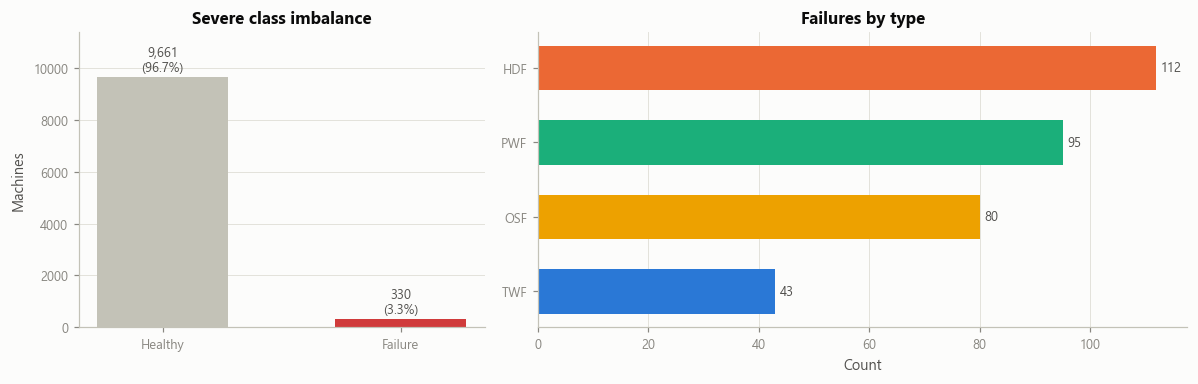

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1, 1.6]})
ax = axes[0]
vc = df["is_failure"].value_counts().sort_index()
bars = ax.bar(["Healthy", "Failure"], vc.values, color=[CLASS_COLORS["No Failure"], CRITICAL], width=0.55)
ax.bar_label(bars, labels=[f"{v:,}\n({v/len(df):.1%})" for v in vc.values], color=INK2, fontsize=8.5, padding=2)
ax.set_title("Severe class imbalance"); ax.set_ylabel("Machines"); ax.set_ylim(0, vc.max() * 1.18); ax.grid(axis="x", visible=False)

ax = axes[1]
fc = counts.drop("No Failure").sort_values()
bars = ax.barh(fc.index, fc.values, color=[CLASS_COLORS[c] for c in fc.index], height=0.6)
ax.bar_label(bars, color=INK2, fontsize=8.5, padding=3)
ax.set_title("Failures by type"); ax.set_xlabel("Count"); ax.grid(axis="y", visible=False)
save(fig, "01_class_balance")

## 4. Exploratory data analysis

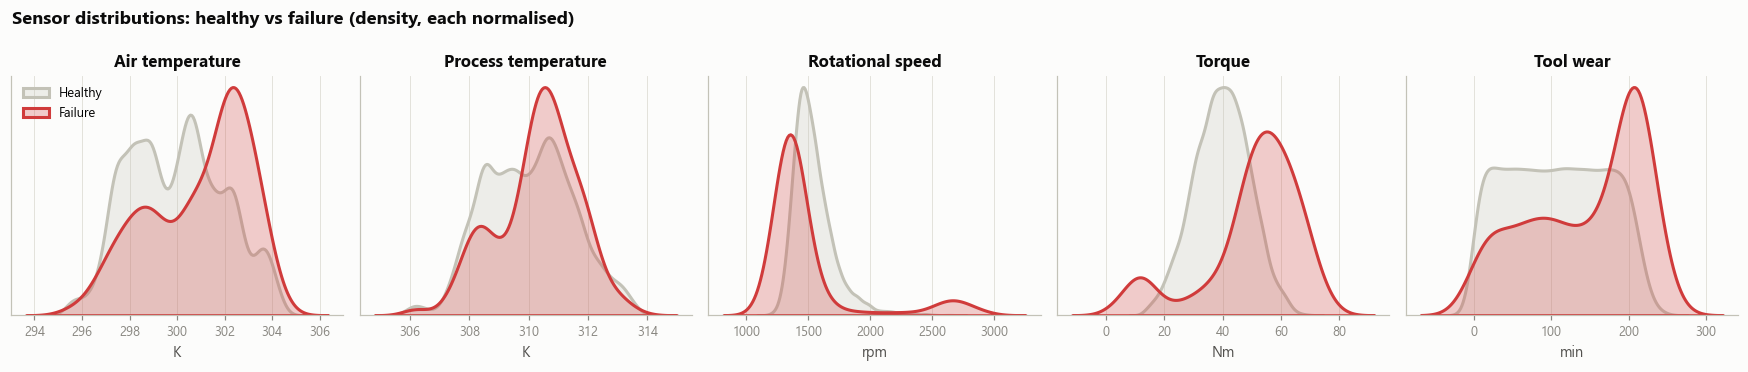

In [7]:
SENSORS = ["Air temperature", "Process temperature", "Rotational speed", "Torque", "Tool wear"]
UNITS = {"Air temperature": "K", "Process temperature": "K", "Rotational speed": "rpm", "Torque": "Nm", "Tool wear": "min"}

fig, axes = plt.subplots(1, 5, figsize=(16, 3.4))
for ax, s in zip(axes, SENSORS):
    for lab, col, name in [(0, CLASS_COLORS["No Failure"], "Healthy"), (1, CRITICAL, "Failure")]:
        sns.kdeplot(df.loc[df.is_failure == lab, s], ax=ax, color=col, fill=True, alpha=.25, linewidth=2,
                    common_norm=False, label=name)
    ax.set_title(s); ax.set_xlabel(UNITS[s]); ax.set_ylabel("")
    ax.set_yticks([])
axes[0].legend()
fig.suptitle("Sensor distributions: healthy vs failure (density, each normalised)", fontweight="bold", color=INK, x=0.01, ha="left")
save(fig, "02_sensor_kde")

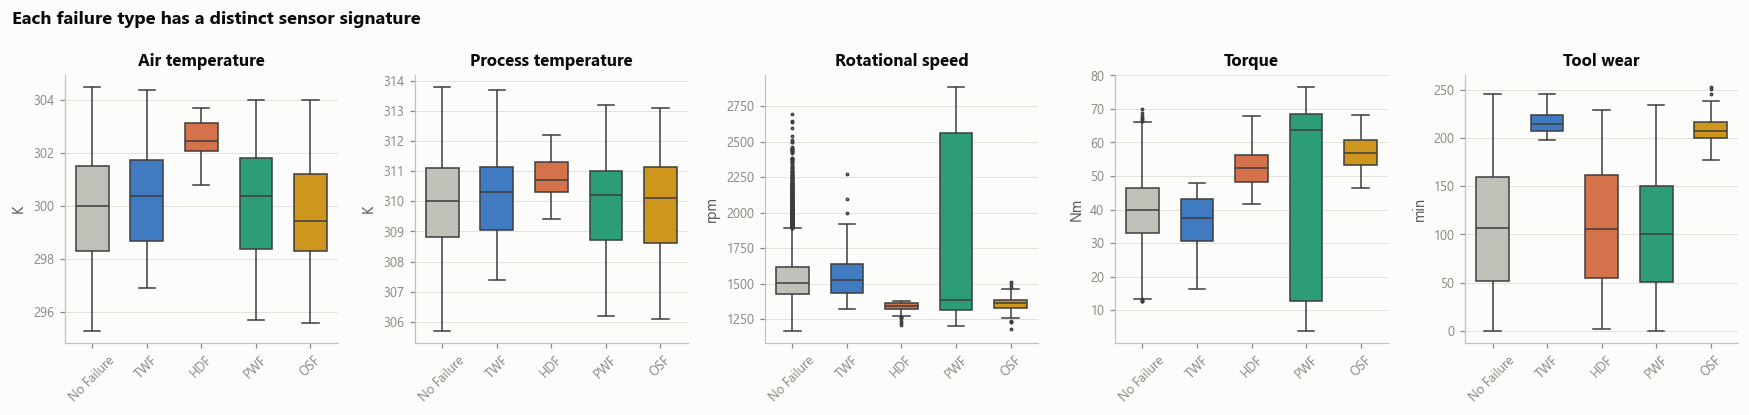

In [8]:
fig, axes = plt.subplots(1, 5, figsize=(16, 3.8), sharey=False)
order = FAILURE_CLASSES
for ax, s in zip(axes, SENSORS):
    sns.boxplot(data=df, x="failure_type", y=s, order=order, ax=ax, palette=CLASS_COLORS,
                fliersize=1.5, linewidth=1, width=0.6)
    ax.set_title(s); ax.set_xlabel(""); ax.set_ylabel(UNITS[s]); ax.tick_params(axis="x", rotation=45)
fig.suptitle("Each failure type has a distinct sensor signature", fontweight="bold", color=INK, x=0.01, ha="left")
save(fig, "03_sensor_boxplots_by_type")

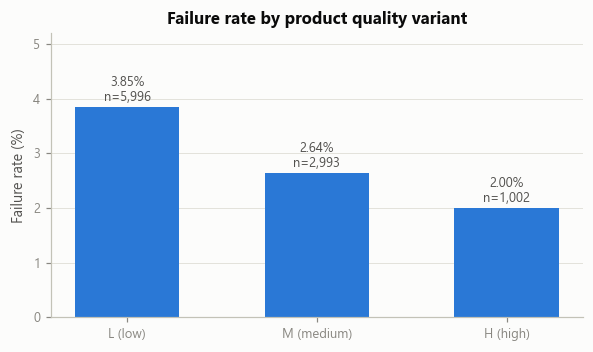

In [9]:
rate = df.groupby("Type")["is_failure"].mean().reindex(["L", "M", "H"]) * 100
n = df["Type"].value_counts().reindex(["L", "M", "H"])
fig, ax = plt.subplots(figsize=(5.5, 3.3))
bars = ax.bar(["L (low)", "M (medium)", "H (high)"], rate.values, color=BLUE, width=0.55)
ax.bar_label(bars, labels=[f"{r:.2f}%\nn={k:,}" for r, k in zip(rate, n)], color=INK2, fontsize=8.5, padding=2)
ax.set_ylabel("Failure rate (%)"); ax.set_ylim(0, rate.max() * 1.35); ax.grid(axis="x", visible=False)
ax.set_title("Failure rate by product quality variant")
save(fig, "04_failure_rate_by_type")

### Pairplot

A pairplot on a stratified sample shows the joint structure. Failures sit at the **edges** of the operating envelope: low speed with high torque, high torque with high wear, and so on.

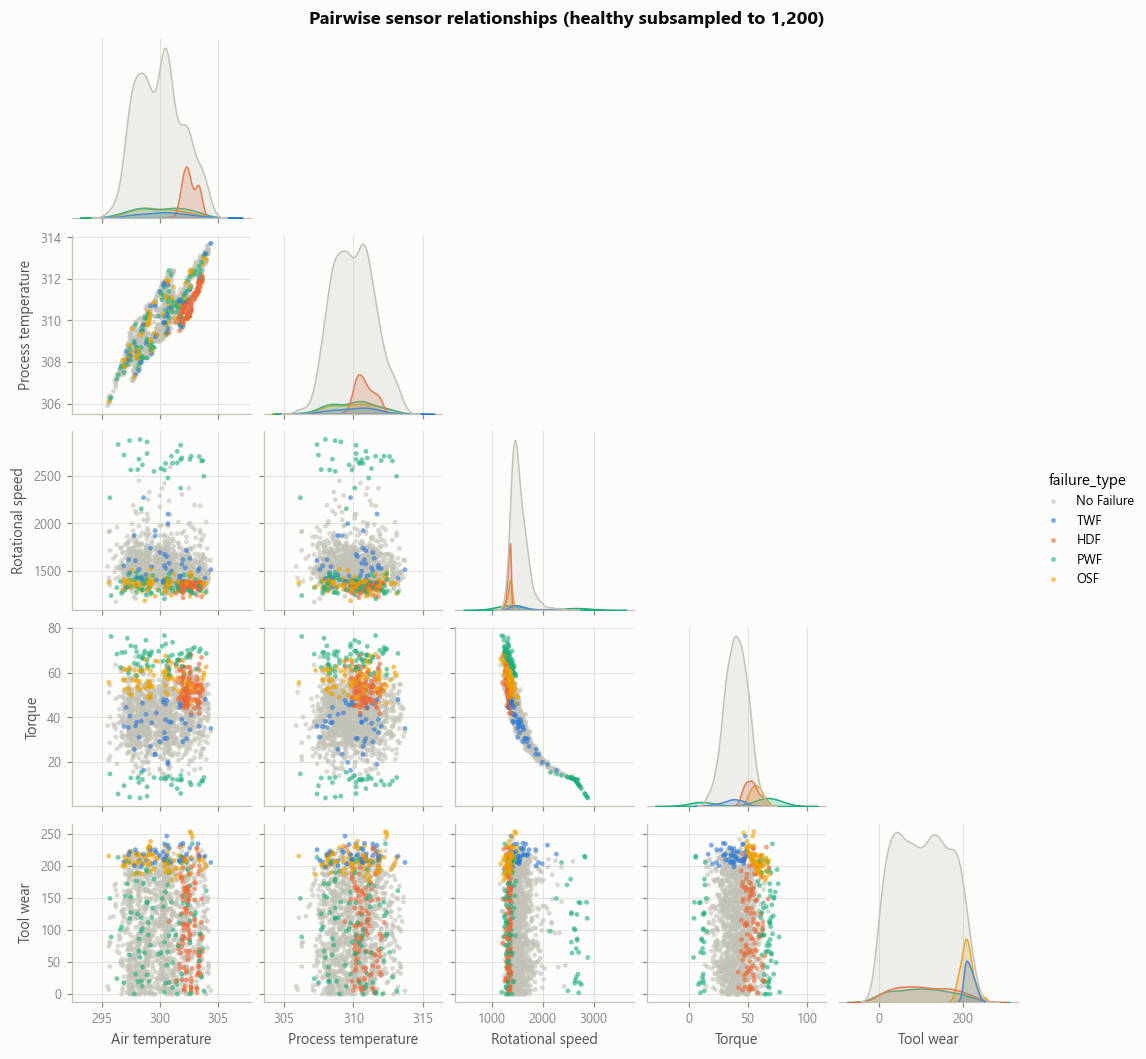

In [10]:
sample = pd.concat([df[df.is_failure == 0].sample(1200, random_state=SEED), df[df.is_failure == 1]])
pp = sns.pairplot(sample, vars=SENSORS, hue="failure_type", hue_order=FAILURE_CLASSES, palette=CLASS_COLORS,
                  plot_kws=dict(s=10, alpha=.6, linewidth=0), diag_kind="kde", corner=True, height=1.9)
pp.figure.suptitle("Pairwise sensor relationships (healthy subsampled to 1,200)", fontweight="bold", color=INK, y=1.01)
pp.figure.savefig(FIG_DIR / "05_pairplot.png", bbox_inches="tight"); plt.show()

### The failure mechanisms, made visible

Each failure mode leaves a geometric signature. One panel per mode isolates that mode against healthy machines. These patterns motivate the engineered features in section 5.

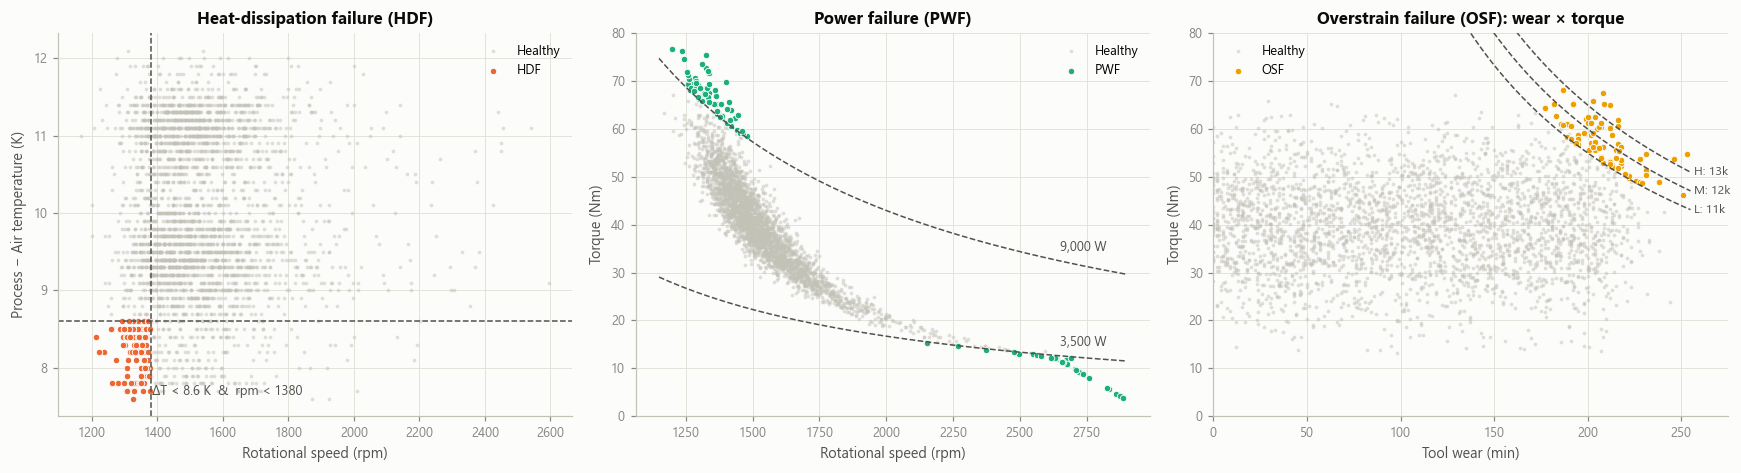

In [11]:
healthy = df[df.is_failure == 0].sample(3000, random_state=SEED)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))

# HDF: temperature difference vs speed
ax = axes[0]; f = df[df.failure_type == "HDF"]
ax.scatter(healthy["Rotational speed"], healthy["Process temperature"] - healthy["Air temperature"], s=6, c=CLASS_COLORS["No Failure"], alpha=.5, label="Healthy", linewidths=0)
ax.scatter(f["Rotational speed"], f["Process temperature"] - f["Air temperature"], s=18, c=CLASS_COLORS["HDF"], label="HDF", edgecolors="#fcfcfb", linewidths=.6)
ax.axhline(8.6, color=INK2, ls="--", lw=1); ax.axvline(1380, color=INK2, ls="--", lw=1)
ax.text(1385, 7.65, "ΔT < 8.6 K  &  rpm < 1380", color=INK2, fontsize=8.5)
ax.set_xlabel("Rotational speed (rpm)"); ax.set_ylabel("Process − Air temperature (K)"); ax.set_title("Heat-dissipation failure (HDF)"); ax.legend(loc="upper right")

# PWF: torque vs speed with power iso-lines
ax = axes[1]; f = df[df.failure_type == "PWF"]
ax.scatter(healthy["Rotational speed"], healthy["Torque"], s=6, c=CLASS_COLORS["No Failure"], alpha=.5, label="Healthy", linewidths=0)
ax.scatter(f["Rotational speed"], f["Torque"], s=18, c=CLASS_COLORS["PWF"], label="PWF", edgecolors="#fcfcfb", linewidths=.6)
rpm_grid = np.linspace(1150, 2900, 200)
for P in (3500, 9000):
    ax.plot(rpm_grid, P / (rpm_grid * 2 * np.pi / 60), color=INK2, ls="--", lw=1)
    ax.text(2650, P / (2650 * 2 * np.pi / 60) + 2, f"{P:,} W", color=INK2, fontsize=8.5)
ax.set_ylim(0, 80); ax.set_xlabel("Rotational speed (rpm)"); ax.set_ylabel("Torque (Nm)"); ax.set_title("Power failure (PWF)"); ax.legend(loc="upper right")

# OSF: wear x torque by type
ax = axes[2]; f = df[df.failure_type == "OSF"]
ax.scatter(healthy["Tool wear"], healthy["Torque"], s=6, c=CLASS_COLORS["No Failure"], alpha=.5, label="Healthy", linewidths=0)
ax.scatter(f["Tool wear"], f["Torque"], s=18, c=CLASS_COLORS["OSF"], label="OSF", edgecolors="#fcfcfb", linewidths=.6)
w = np.linspace(60, 255, 200)
for t, lim in OSF_LIMIT.items():
    ax.plot(w, lim / w, color=INK2, ls="--", lw=1); ax.text(w[-1] + 2, lim / w[-1], f"{t}: {lim//1000}k", color=INK2, fontsize=8, va="center")
ax.set_ylim(0, 80); ax.set_xlim(0, 275); ax.set_xlabel("Tool wear (min)"); ax.set_ylabel("Torque (Nm)"); ax.set_title("Overstrain failure (OSF): wear × torque"); ax.legend(loc="upper left")
save(fig, "06_failure_mechanisms")

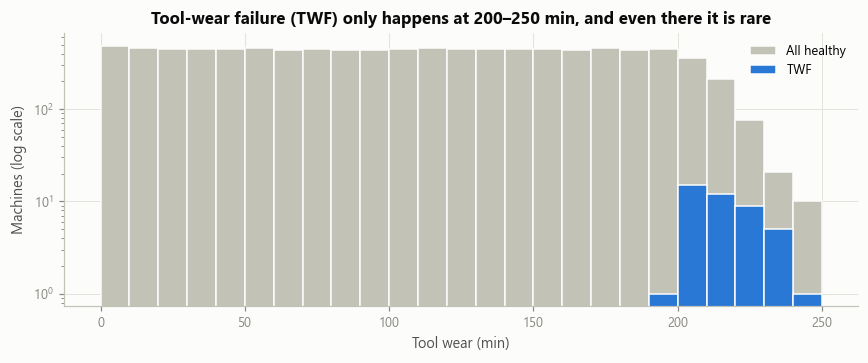

Rows with tool wear >= 200 min: 800 | TWF among them: 42 (5.2%)


In [12]:
fig, ax = plt.subplots(figsize=(8, 3.4))
bins = np.arange(0, 260, 10)
ax.hist(df.loc[df.is_failure == 0, "Tool wear"], bins=bins, color=CLASS_COLORS["No Failure"], label="All healthy", edgecolor="#fcfcfb", linewidth=1)
ax2_counts = df.loc[df.failure_type == "TWF", "Tool wear"]
ax.hist(ax2_counts, bins=bins, color=CLASS_COLORS["TWF"], label="TWF", edgecolor="#fcfcfb", linewidth=1)
ax.set_yscale("log"); ax.set_xlabel("Tool wear (min)"); ax.set_ylabel("Machines (log scale)")
ax.set_title("Tool-wear failure (TWF) only happens at 200–250 min, and even there it is rare"); ax.legend()
save(fig, "07_twf_window")
w200 = df["Tool wear"] >= 200
print(f"Rows with tool wear >= 200 min: {w200.sum()} | TWF among them: {(df.failure_type[w200]=='TWF').sum()} "
      f"({(df.failure_type[w200]=='TWF').mean():.1%})")

**Key EDA takeaways**

* **HDF, PWF and OSF** are **deterministic**: they appear exactly where physical thresholds are crossed. Once the right derived features exist, they should be separable almost perfectly.
* **TWF** happens at a *random* point inside the 200–240 min wear window. Even in that window only about 6% of machines fail. Raising alarms for it would flood operators with false alarms, so it is treated as a **scheduled tool-replacement advisory**, backed by the RUL model in section 14, not as a hard alarm.
* Quality variant L has the highest failure rate, which matches its lower OSF strain limit.

## 5. Feature engineering (physics-informed)

All features are built in [`src/features.py`](../src/features.py) by `build_features()`. The future FastAPI service will call the same function, so training and inference cannot diverge.

| Feature | Formula | Targets |
|---|---|---|
| `temp_diff` | Process − Air temperature | HDF |
| `power_W` | Torque × rpm × 2π/60 | PWF |
| `wear_x_torque` | Tool wear × Torque | OSF |
| `osf_margin` | type limit (11k/12k/13k) − wear×torque | OSF |
| `power_margin_low/high` | P − 3500, 9000 − P | PWF |
| `hdf_temp_margin`, `hdf_rpm_margin` | ΔT − 8.6, rpm − 1380 | HDF |
| `tool_wear_margin` | 200 − wear | TWF |
| `type_ord` | L=0, M=1, H=2 | all |

In [13]:
X_all = build_features(df)
y_all = df["target"].values
yb_all = df["is_failure"].values
RAW_FEATS = ["air_temp", "process_temp", "rpm", "torque", "tool_wear", "type_ord"]
ENG_FEATS = list(X_all.columns)
print(f"{len(RAW_FEATS)} raw features -> {len(ENG_FEATS)} engineered features")
display(X_all.head().round(2))

6 raw features -> 15 engineered features


,air_temp,process_temp,rpm,torque,tool_wear,temp_diff,power_W,wear_x_torque,osf_margin,power_margin_low,power_margin_high,hdf_temp_margin,hdf_rpm_margin,tool_wear_margin,type_ord
0,298.1,308.6,1551,42.8,0,10.5,6951.59,0.0,12000.0,3451.59,2048.41,1.9,171,200,1
1,298.2,308.7,1408,46.3,3,10.5,6826.72,138.9,10861.1,3326.72,2173.28,1.9,28,197,0
2,298.1,308.5,1498,49.4,5,10.4,7749.39,247.0,10753.0,4249.39,1250.61,1.8,118,195,0
3,298.2,308.6,1433,39.5,7,10.4,5927.50,276.5,10723.5,2427.50,3072.50,1.8,53,193,0
4,298.2,308.7,1408,40.0,9,10.5,5897.82,360.0,10640.0,2397.82,3102.18,1.9,28,191,0


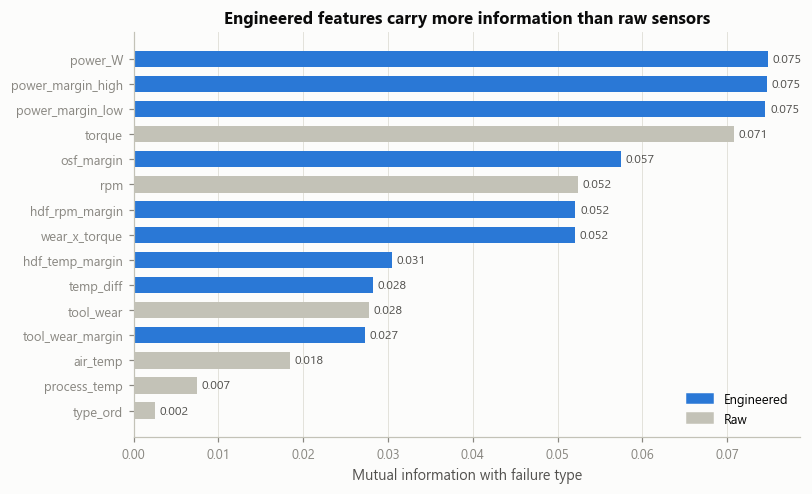

In [14]:
mi = pd.Series(mutual_info_classif(X_all, y_all, random_state=SEED, discrete_features=False), index=ENG_FEATS).sort_values()
fig, ax = plt.subplots(figsize=(7.5, 4.6))
cols = [BLUE if c not in RAW_FEATS else CLASS_COLORS["No Failure"] for c in mi.index]
bars = ax.barh(mi.index, mi.values, color=cols, height=0.65)
ax.bar_label(bars, fmt="%.3f", color=INK2, fontsize=8, padding=3)
ax.set_xlabel("Mutual information with failure type"); ax.grid(axis="y", visible=False)
ax.set_title("Engineered features carry more information than raw sensors")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=BLUE, label="Engineered"), Patch(color=CLASS_COLORS["No Failure"], label="Raw")], loc="lower right")
save(fig, "08_mutual_information")

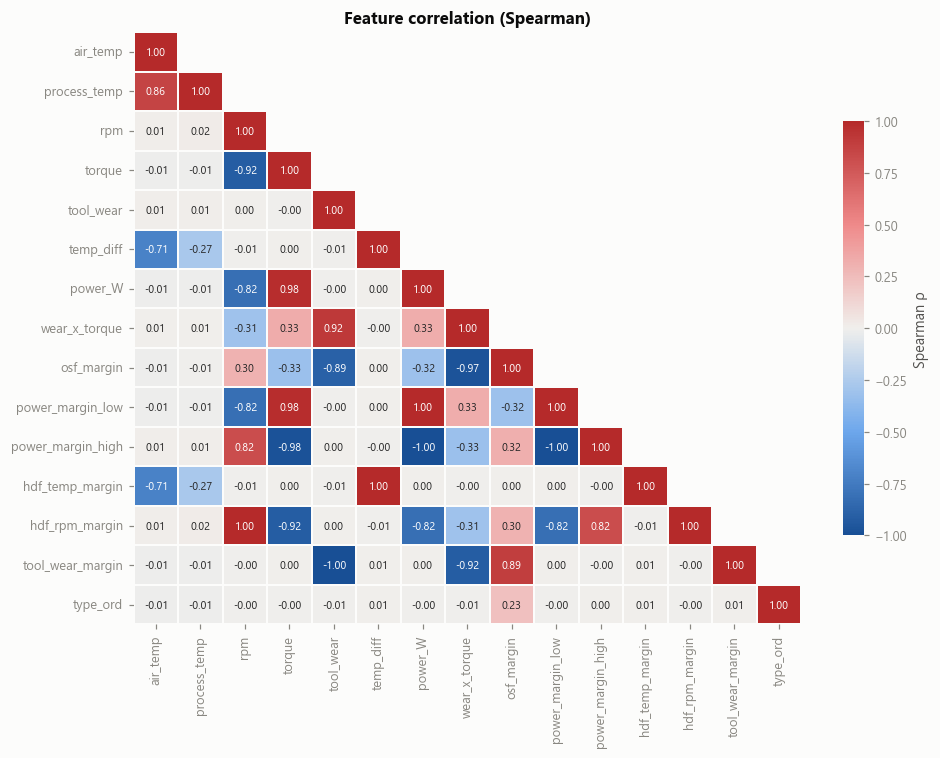

In [15]:
corr = X_all.corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 7))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, cmap=DIV, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f", annot_kws={"size": 7},
            linewidths=1, linecolor="#fcfcfb", cbar_kws={"shrink": .7, "label": "Spearman ρ"}, ax=ax)
ax.set_title("Feature correlation (Spearman)"); ax.grid(False)
save(fig, "09_feature_correlation")

## 6. Train / test split

The split is a stratified 80/20 on the 5-class target. **The test set is touched only once, in section 11.** All model selection, tuning and threshold choice use 5-fold stratified cross-validation on the training set (out-of-fold predictions).

In [16]:
idx_tr, idx_te = train_test_split(np.arange(len(df)), test_size=0.2, stratify=y_all, random_state=SEED)
X_tr, X_te = X_all.iloc[idx_tr].reset_index(drop=True), X_all.iloc[idx_te].reset_index(drop=True)
y_tr, y_te = y_all[idx_tr], y_all[idx_te]
yb_tr, yb_te = (y_tr > 0).astype(int), (y_te > 0).astype(int)
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print(f"Train: {len(X_tr):,} ({yb_tr.sum()} failures) | Test: {len(X_te):,} ({yb_te.sum()} failures)")
display(pd.DataFrame({"train": pd.Series(y_tr).map(dict(enumerate(FAILURE_CLASSES))).value_counts(),
                      "test": pd.Series(y_te).map(dict(enumerate(FAILURE_CLASSES))).value_counts()}).reindex(FAILURE_CLASSES))

Train: 7,992 (264 failures) | Test: 1,999 (66 failures)


,train,test
No Failure,7728,1933
TWF,34,9
HDF,90,22
PWF,76,19
OSF,64,16


In [17]:
def binary_metrics(y_true_bin, p_fail, thr=0.5):
    # Alarm metrics from failure probability (1 - P(No Failure))
    pred = (p_fail >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true_bin, pred, labels=[0, 1]).ravel()
    return {"Accuracy": (tp + tn) / len(pred), "Precision": tp / max(tp + fp, 1), "Recall": tp / max(tp + fn, 1),
            "F1": f1_score(y_true_bin, pred, zero_division=0), "FDR": fp / max(tp + fp, 1),
            "MCC": matthews_corrcoef(y_true_bin, pred), "PR-AUC": average_precision_score(y_true_bin, p_fail),
            "TP": tp, "FP": fp, "FN": fn}

def oof_proba(model, X, y, cv=CV):
    return cross_val_predict(model, X, y, cv=cv, method="predict_proba")

## 7. Anomaly detection (unsupervised)

Before any labels are used, can failures be spotted as **outliers from normal operation**? IsolationForest and Local Outlier Factor (novelty mode) are trained on **healthy training machines only**, then scored on the test set. This is a useful fallback for failure modes never seen during training.

,ROC-AUC,PR-AUC
IsolationForest,0.900,0.363
LOF,0.891,0.460


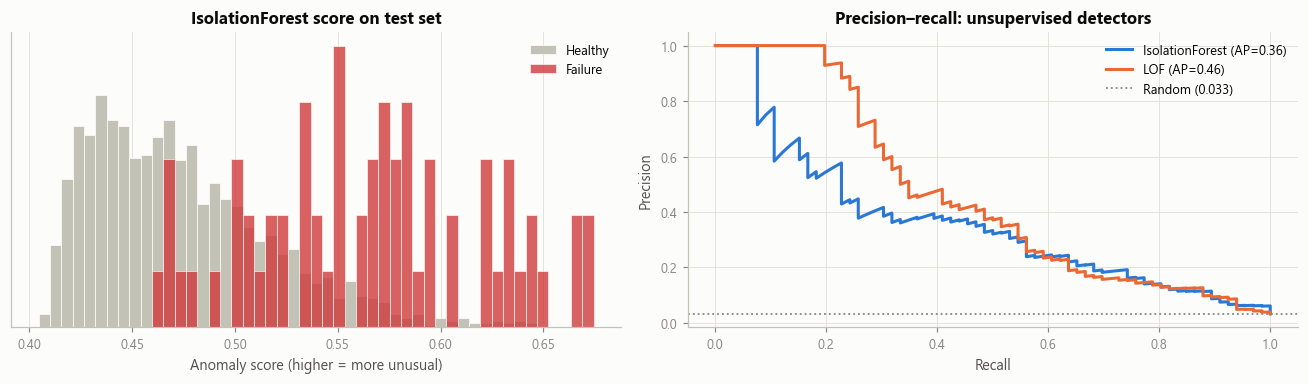

In [18]:
scaler_ad = StandardScaler().fit(X_tr[yb_tr == 0])
Xh = scaler_ad.transform(X_tr[yb_tr == 0])
iso = IsolationForest(n_estimators=400, contamination="auto", random_state=SEED).fit(Xh)
lof = LocalOutlierFactor(n_neighbors=35, novelty=True).fit(Xh)

Xte_s = scaler_ad.transform(X_te)
scores = {"IsolationForest": -iso.score_samples(Xte_s), "LOF": -lof.score_samples(Xte_s)}
ad_res = pd.DataFrame({k: {"ROC-AUC": roc_auc_score(yb_te, s), "PR-AUC": average_precision_score(yb_te, s)} for k, s in scores.items()}).T
display(ad_res.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
ax = axes[0]
s = scores["IsolationForest"]
bins = np.linspace(s.min(), s.max(), 50)
ax.hist(s[yb_te == 0], bins=bins, color=CLASS_COLORS["No Failure"], density=True, label="Healthy", edgecolor="#fcfcfb", linewidth=.5)
ax.hist(s[yb_te == 1], bins=bins, color=CRITICAL, alpha=.8, density=True, label="Failure", edgecolor="#fcfcfb", linewidth=.5)
ax.set_xlabel("Anomaly score (higher = more unusual)"); ax.set_yticks([]); ax.set_title("IsolationForest score on test set"); ax.legend()
ax = axes[1]
for (k, s), c in zip(scores.items(), [BLUE, ORANGE]):
    p, r, _ = precision_recall_curve(yb_te, s); ax.plot(r, p, color=c, label=f"{k} (AP={average_precision_score(yb_te, s):.2f})")
ax.axhline(yb_te.mean(), color=MUTED, ls=":", lw=1.2, label=f"Random ({yb_te.mean():.3f})")
ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.set_title("Precision–recall: unsupervised detectors"); ax.legend()
save(fig, "10_anomaly_detection")

Both detectors beat random by a wide margin, and failures clearly sit in the tail of the score distribution. Their precision is still far too low for a production alarm. **Supervised, cost-sensitive learning is needed to reach a low FDR.** Below, the anomaly score is tested as an extra feature for the supervised model.

In [19]:
def iso_score_feature(Xa, Xb, ya):
    sc = StandardScaler().fit(Xa[ya == 0]); m = IsolationForest(n_estimators=300, random_state=SEED).fit(sc.transform(Xa[ya == 0]))
    return -m.score_samples(sc.transform(Xb))

# Out-of-fold anomaly feature (fit on each training fold only -> no leakage)
iso_oof = np.zeros(len(X_tr))
for tr, va in CV.split(X_tr, y_tr):
    iso_oof[va] = iso_score_feature(X_tr.iloc[tr], X_tr.iloc[va], yb_tr[tr])

lgb_base = lgb.LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=15, random_state=SEED, verbose=-1)
p0 = 1 - oof_proba(lgb_base, X_tr, y_tr)[:, 0]
p1 = 1 - oof_proba(lgb_base, X_tr.assign(iso_score=iso_oof), y_tr)[:, 0]
display(pd.DataFrame({"Engineered": binary_metrics(yb_tr, p0), "Engineered + anomaly score": binary_metrics(yb_tr, p1)}).T.round(4))

,Accuracy,Precision,Recall,F1,FDR,MCC,PR-AUC,TP,FP,FN
Engineered,0.9951,0.9747,0.8750,0.9222,0.0253,0.9211,0.9234,231.0,6.0,33.0
Engineered + anomaly score,0.9951,0.9828,0.8674,0.9215,0.0172,0.9209,0.9212,229.0,4.0,35.0


The anomaly score adds **no measurable gain** on top of the physics features. It is left out of the final model to keep it simpler (Occam's razor).

## 8. Baseline model comparison

Four model families are compared on **raw sensors** and on **engineered features**, using 5-fold out-of-fold predictions on the training set. The alarm fires when `P(failure) = 1 − P(No Failure) ≥ 0.5`.

In [20]:
def make_models():
    return {
        "LogisticRegression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=1.0)),
        "RandomForest": RandomForestClassifier(n_estimators=400, min_samples_leaf=1, n_jobs=-1, random_state=SEED),
        "XGBoost": xgb.XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=5, subsample=0.9,
                                     colsample_bytree=0.9, eval_metric="mlogloss", random_state=SEED, n_jobs=-1),
        "LightGBM": lgb.LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=15, random_state=SEED, verbose=-1),
    }

rows, OOF = [], {}
for fs_name, feats in [("Raw", RAW_FEATS), ("Engineered", ENG_FEATS)]:
    for name, model in make_models().items():
        proba = oof_proba(model, X_tr[feats], y_tr)
        OOF[(fs_name, name)] = proba
        m = binary_metrics(yb_tr, 1 - proba[:, 0])
        m["Macro-F1 (5 class)"] = f1_score(y_tr, proba.argmax(1), average="macro")
        rows.append({"Features": fs_name, "Model": name, **m})
baseline = pd.DataFrame(rows).set_index(["Features", "Model"])
display(baseline.style.format({c: "{:.4f}" for c in baseline.columns if c not in ("TP", "FP", "FN")})
        .background_gradient(subset=["FDR"], cmap="Reds").background_gradient(subset=["Recall", "MCC"], cmap="Blues"))

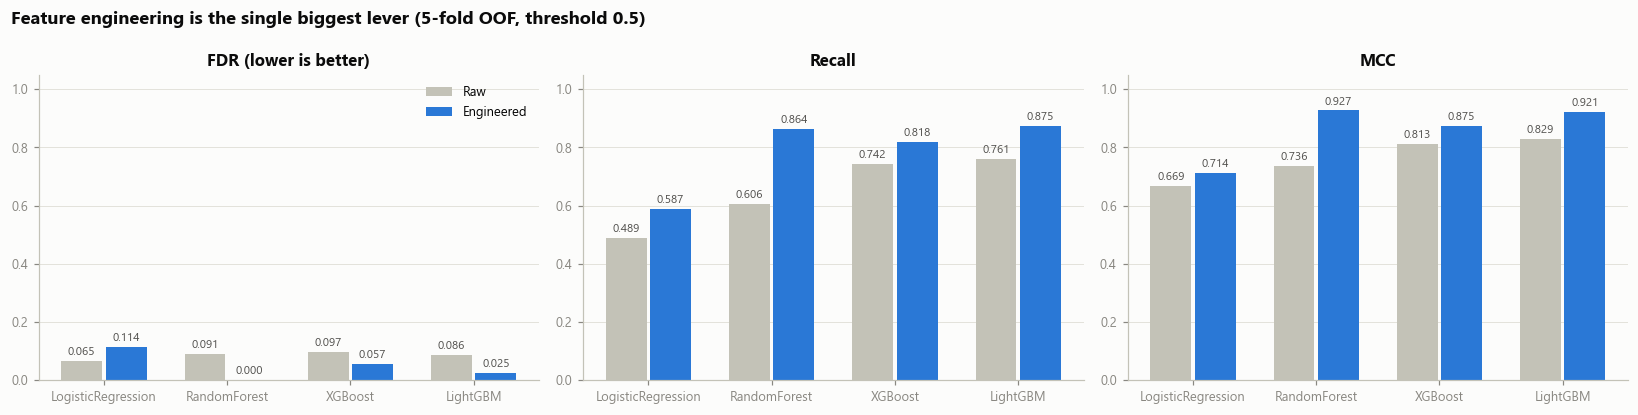

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
models = list(make_models())
x = np.arange(len(models)); wdt = 0.36
for ax, metric in zip(axes, ["FDR", "Recall", "MCC"]):
    for i, (fs, col) in enumerate([("Raw", CLASS_COLORS["No Failure"]), ("Engineered", BLUE)]):
        vals = baseline.loc[fs, metric].reindex(models).values
        b = ax.bar(x + (i - .5) * wdt, vals, wdt * 0.92, color=col, label=fs)
        ax.bar_label(b, fmt="%.3f", fontsize=7.5, color=INK2, padding=2)
    ax.set_xticks(x); ax.set_xticklabels(models, fontsize=8.5); ax.set_title(metric + (" (lower is better)" if metric == "FDR" else ""))
    ax.grid(axis="x", visible=False); ax.set_ylim(0, max(1.05, ax.get_ylim()[1]))
axes[0].legend(loc="upper right")
fig.suptitle("Feature engineering is the single biggest lever (5-fold OOF, threshold 0.5)", fontweight="bold", color=INK, x=0.01, ha="left")
save(fig, "11_baseline_comparison")

**Observations**

* With raw sensors, even the strong boosters leave many failures undetected and produce more false alarms.
* Engineered features improve **every** model. Tree ensembles benefit most: LightGBM's MCC rises from ≈0.83 to ≈0.92 and its false alarms drop sharply.
* With engineered features, **LightGBM** has the best recall, MCC and macro-F1. **Random Forest** raises zero false alarms at 0.5 but misses more failures. The remaining misses for the boosters are almost entirely the stochastic TWF.
* Logistic regression gains little: the failure rules are *interaction thresholds*, which a linear model cannot represent.

**LightGBM** is carried forward: it is the most accurate, it is fast, and it supports cost-sensitive weighting natively. Its false alarms are then removed by tuning (section 9) and threshold selection (section 10).

## 9. Cost-sensitive learning & hyper-parameter tuning

### 9.1 Business cost matrix (assumptions)

| | Predicted OK | Predicted failure (alarm) |
|---|---|---|
| **Actually OK** | 0 | **C_FP = 10 k€**: unnecessary stop, inspection, lost output |
| **Actually failing** | **C_FN = 30 k€**: unplanned breakdown, repair | **C_TP = 2 k€**: planned intervention |

The values are illustrative and can be changed in the cell below. The FDR constraint is applied **on top** of the cost: an alarm system that cries wolf is ignored by operators, whatever the money.

### 9.2 Imbalance strategies

Three strategies are compared:
- no re-weighting
- class weights (`class_weight="balanced"`, the cost-sensitive loss)
- SMOTE oversampling, inside the CV folds so that it does not leak

In [22]:
C_FP, C_FN, C_TP = 10_000, 30_000, 2_000
def business_cost(y_true_bin, p_fail, thr):
    pred = p_fail >= thr
    return C_FP * (pred & (y_true_bin == 0)).sum() + C_FN * (~pred & (y_true_bin == 1)).sum() + C_TP * (pred & (y_true_bin == 1)).sum()

lgb_params = dict(n_estimators=400, learning_rate=0.05, num_leaves=15, random_state=SEED, verbose=-1)
strategies = {
    "None": lgb.LGBMClassifier(**lgb_params),
    "Class weights (balanced)": lgb.LGBMClassifier(**lgb_params, class_weight="balanced"),
    "SMOTE": ImbPipeline([("smote", SMOTE(random_state=SEED, k_neighbors=5)), ("clf", lgb.LGBMClassifier(**lgb_params))]),
}
rows = []
for name, model in strategies.items():
    p = 1 - oof_proba(model, X_tr, y_tr)[:, 0]
    rows.append({"Strategy": name, **binary_metrics(yb_tr, p), "Cost @0.5 (k€)": business_cost(yb_tr, p, 0.5) / 1e3})
imb = pd.DataFrame(rows).set_index("Strategy")
display(imb.round(4))

,Accuracy,Precision,Recall,F1,FDR,MCC,PR-AUC,TP,FP,FN,Cost @0.5 (k€)
Strategy,,,,,,,,,,,
None,0.9951,0.9747,0.8750,0.9222,0.0253,0.9211,0.9234,231,6,33,1512.0
Class weights (balanced),0.9945,0.9545,0.8750,0.9130,0.0455,0.9111,0.9186,231,11,33,1562.0
SMOTE,0.9864,0.7460,0.8902,0.8117,0.2540,0.8081,0.9319,235,80,29,2140.0


Class weighting adds false alarms **without any recall gain**. SMOTE buys a few extra detections at the cost of many more false alarms. Both push probability mass towards the failure classes, and that mostly creates TWF false positives. Since the priority is a low FDR, **no re-weighting is applied**. The trade-off is controlled explicitly with the decision threshold in section 10 instead.

### 9.3 Hyper-parameter tuning with Optuna

The objective is the **out-of-fold business cost**, with a hard penalty whenever the out-of-fold FDR goes above 5%. This makes the cost and FDR goals part of the search itself.

In [23]:
CV3 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED + 1)
def objective(trial):
    params = dict(
        n_estimators=trial.suggest_int("n_estimators", 150, 900, step=50),
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        num_leaves=trial.suggest_int("num_leaves", 7, 63),
        min_child_samples=trial.suggest_int("min_child_samples", 3, 40),
        subsample=trial.suggest_float("subsample", 0.6, 1.0), subsample_freq=1,
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.5, 1.0),
        reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
        random_state=SEED, verbose=-1)
    p = 1 - oof_proba(lgb.LGBMClassifier(**params), X_tr, y_tr, cv=CV3)[:, 0]
    m = binary_metrics(yb_tr, p, 0.5)
    trial.set_user_attr("FDR", m["FDR"]); trial.set_user_attr("Recall", m["Recall"])
    return business_cost(yb_tr, p, 0.5) + (1e6 if m["FDR"] > 0.05 else 0)

study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED))
study.enqueue_trial({"n_estimators": 400, "learning_rate": 0.05, "num_leaves": 15, "min_child_samples": 20,
                     "subsample": 1.0, "colsample_bytree": 1.0, "reg_lambda": 1e-3})   # baseline as first trial
study.optimize(objective, n_trials=40, show_progress_bar=False)

best_params = {**study.best_params, "subsample_freq": 1, "random_state": SEED, "verbose": -1}
print(f"Best OOF cost: {study.best_value/1e3:,.0f} k€ | FDR={study.best_trial.user_attrs['FDR']:.4f} | Recall={study.best_trial.user_attrs['Recall']:.4f}")
print(best_params)

Best OOF cost: 1,480 k€ | FDR=0.0000 | Recall=0.8712
{'n_estimators': 600, 'learning_rate': 0.011492999300221412, 'num_leaves': 41, 'min_child_samples': 9, 'subsample': 0.6260206371941118, 'colsample_bytree': 0.9744427686266666, 'reg_lambda': 7.2866537374910445, 'subsample_freq': 1, 'random_state': 42, 'verbose': -1}


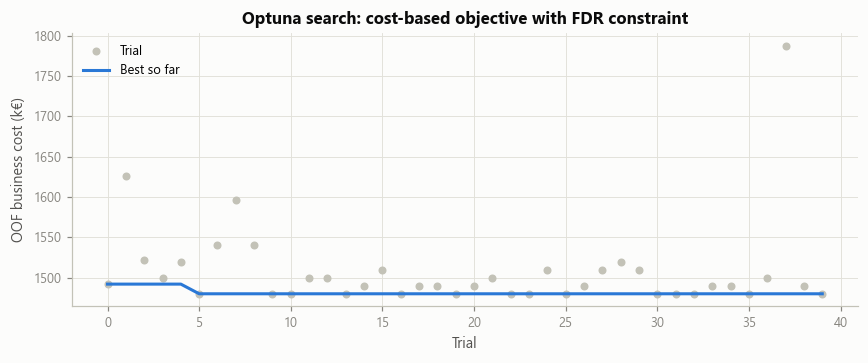

In [24]:
hist = study.trials_dataframe()
hist = hist[hist["user_attrs_FDR"] <= 0.05]   # drop trials that violated the FDR constraint (penalised)
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.scatter(hist["number"], hist["value"] / 1e3, s=18, color=CLASS_COLORS["No Failure"], label="Trial", zorder=2)
ax.plot(hist["number"], (hist["value"].cummin()) / 1e3, color=BLUE, label="Best so far", zorder=3)
ax.set_xlabel("Trial"); ax.set_ylabel("OOF business cost (k€)"); ax.set_title("Optuna search: cost-based objective with FDR constraint"); ax.legend()
save(fig, "12_optuna_history")

## 10. FDR-driven threshold tuning

The decision rule is **two-stage**:

1. **Alarm?** `P(failure) = 1 − P(No Failure) ≥ τ`
2. **Which failure?** `argmax` over the four failure classes, for the cases where an alarm fires

The threshold **τ** is picked on out-of-fold training predictions, never on the test set. The rule is: **maximise recall subject to FDR ≤ 2%**. Among thresholds that reach the same recall, the most conservative (highest) τ wins.

In [25]:
final_model = lgb.LGBMClassifier(**best_params)
oof_final = oof_proba(final_model, X_tr, y_tr)
p_oof = 1 - oof_final[:, 0]

FDR_TARGET = 0.02
grid = np.round(np.arange(0.05, 0.991, 0.01), 2)
curve = pd.DataFrame([{**binary_metrics(yb_tr, p_oof, t), "thr": t, "Cost (k€)": business_cost(yb_tr, p_oof, t) / 1e3} for t in grid]).set_index("thr")
ok = curve[curve["FDR"] <= FDR_TARGET]
best_rec = ok["Recall"].max()
THRESHOLD = float(ok[ok["Recall"] >= best_rec - 1e-9].index.max())
print(f"Selected threshold τ = {THRESHOLD:.2f}")
display(curve.loc[[0.5, THRESHOLD], ["Precision", "Recall", "FDR", "FP", "FN", "MCC", "Cost (k€)"]].round(4))

Selected threshold τ = 0.66


,Precision,Recall,FDR,FP,FN,MCC,Cost (k€)
thr,,,,,,,
0.50,1.0,0.8712,0.0,0,34,0.9313,1480.0
0.66,1.0,0.8712,0.0,0,34,0.9313,1480.0


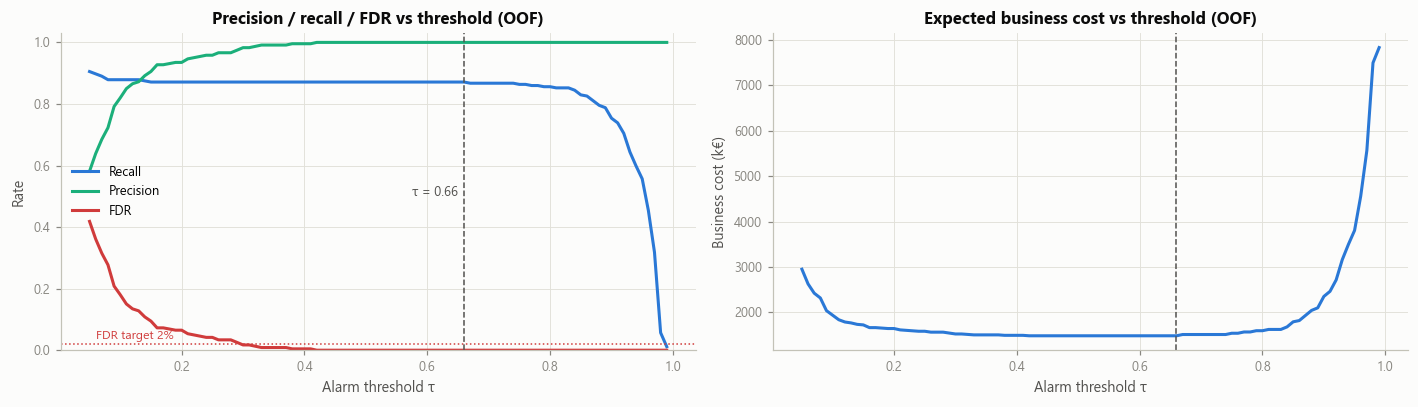

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
ax = axes[0]
ax.plot(curve.index, curve["Recall"], color=BLUE, label="Recall")
ax.plot(curve.index, curve["Precision"], color=CLASS_COLORS["PWF"], label="Precision")
ax.plot(curve.index, curve["FDR"], color=CRITICAL, label="FDR")
ax.axhline(FDR_TARGET, color=CRITICAL, ls=":", lw=1); ax.text(0.06, FDR_TARGET + 0.015, f"FDR target {FDR_TARGET:.0%}", color=CRITICAL, fontsize=8)
ax.axvline(THRESHOLD, color=INK2, ls="--", lw=1); ax.text(THRESHOLD - 0.01, 0.5, f"τ = {THRESHOLD:.2f}", color=INK2, fontsize=8.5, ha="right")
ax.set_xlabel("Alarm threshold τ"); ax.set_ylabel("Rate"); ax.set_ylim(0, 1.03); ax.set_title("Precision / recall / FDR vs threshold (OOF)"); ax.legend(loc="center left")
ax = axes[1]
ax.plot(curve.index, curve["Cost (k€)"], color=BLUE)
ax.axvline(THRESHOLD, color=INK2, ls="--", lw=1)
ax.set_xlabel("Alarm threshold τ"); ax.set_ylabel("Business cost (k€)"); ax.set_title("Expected business cost vs threshold (OOF)")
save(fig, "13_threshold_tuning")

## 11. Final evaluation on the held-out test set

The tuned model is refit on the **full training set** and evaluated **once** on the 20% test set, which it has never seen.

In [27]:
final_model = lgb.LGBMClassifier(**best_params).fit(X_tr, y_tr)
proba_te = final_model.predict_proba(X_te)
p_te = 1 - proba_te[:, 0]

def two_stage_predict(proba, thr):
    alarm = (1 - proba[:, 0]) >= thr
    ftype = proba[:, 1:].argmax(1) + 1
    return np.where(alarm, ftype, 0)

y_pred_te = two_stage_predict(proba_te, THRESHOLD)
summary = pd.DataFrame({
    "Default (argmax / τ=0.5)": binary_metrics(yb_te, p_te, 0.5),
    f"FDR-tuned (τ={THRESHOLD:.2f})": binary_metrics(yb_te, p_te, THRESHOLD),
}).T
summary["Macro-F1 (5 class)"] = [f1_score(y_te, two_stage_predict(proba_te, 0.5), average="macro"),
                                 f1_score(y_te, y_pred_te, average="macro")]
summary["Accuracy (5 class)"] = [accuracy_score(y_te, two_stage_predict(proba_te, 0.5)), accuracy_score(y_te, y_pred_te)]
display(summary.style.format({c: ("{:.0f}" if c in ("TP", "FP", "FN") else "{:.4f}") for c in summary.columns}))

,Accuracy,Precision,Recall,F1,FDR,MCC,PR-AUC,TP,FP,FN,Macro-F1 (5 class),Accuracy (5 class)
Default (argmax / τ=0.5),0.9955,1.0000,0.8636,0.9268,0.0000,0.9272,0.9401,57,0,9,0.7995,0.9955
FDR-tuned (τ=0.66),0.9955,1.0000,0.8636,0.9268,0.0000,0.9272,0.9401,57,0,9,0.7995,0.9955


In [28]:
print(classification_report(y_te, y_pred_te, target_names=FAILURE_CLASSES, digits=4, zero_division=0))
cm = confusion_matrix(y_te, y_pred_te, labels=range(5))
per_class = pd.DataFrame({"Support": cm.sum(1), "Alarms raised": cm.sum(0), "Correct": np.diag(cm)}, index=FAILURE_CLASSES)
per_class["Precision"] = per_class["Correct"] / per_class["Alarms raised"].replace(0, np.nan)
per_class["FDR"] = 1 - per_class["Precision"]
per_class["Recall"] = per_class["Correct"] / per_class["Support"]
display(per_class.iloc[1:].round(4))

              precision    recall  f1-score   support

  No Failure     0.9954    1.0000    0.9977      1933
         TWF     0.0000    0.0000    0.0000         9
         HDF     1.0000    1.0000    1.0000        22
         PWF     1.0000    1.0000    1.0000        19
         OSF     1.0000    1.0000    1.0000        16

    accuracy                         0.9955      1999
   macro avg     0.7991    0.8000    0.7995      1999
weighted avg     0.9910    0.9955    0.9933      1999



,Support,Alarms raised,Correct,Precision,FDR,Recall
TWF,9,0,0,NaN,NaN,0.0
HDF,22,22,22,1.0,0.0,1.0
PWF,19,19,19,1.0,0.0,1.0
OSF,16,16,16,1.0,0.0,1.0


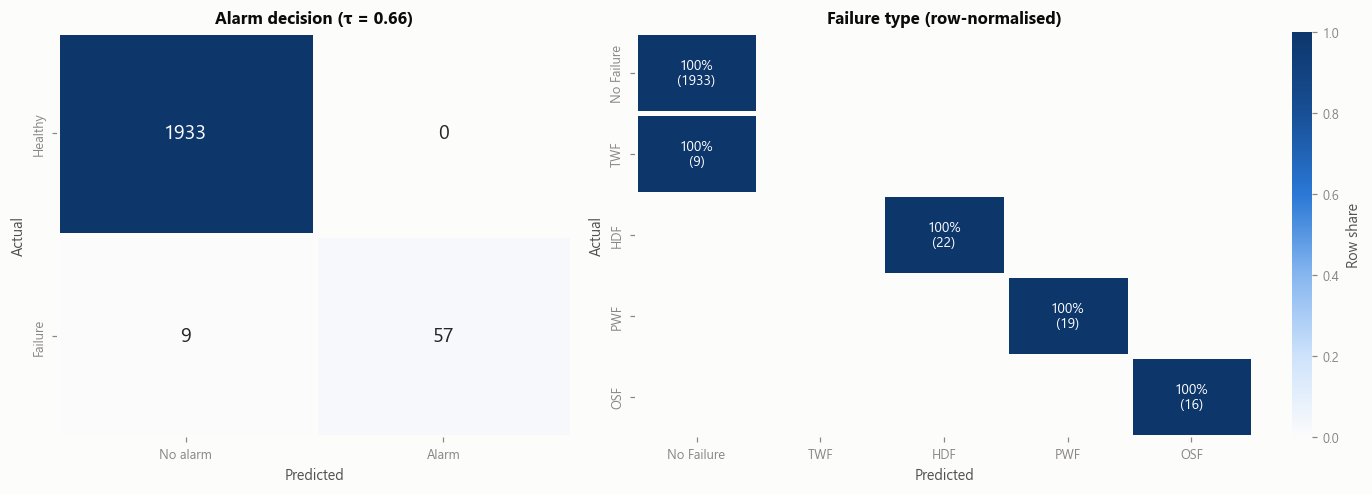

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1, 1.5]})
cmb = confusion_matrix(yb_te, (p_te >= THRESHOLD).astype(int))
sns.heatmap(cmb, annot=True, fmt="d", cmap=SEQ, cbar=False, linewidths=2, linecolor="#fcfcfb",
            xticklabels=["No alarm", "Alarm"], yticklabels=["Healthy", "Failure"], ax=axes[0], annot_kws={"size": 13})
axes[0].set_title(f"Alarm decision (τ = {THRESHOLD:.2f})"); axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual"); axes[0].grid(False)
cmn = cm / cm.sum(1, keepdims=True)
annot = np.array([[f"{cmn[i,j]:.0%}\n({cm[i,j]})" if cm[i, j] else "" for j in range(5)] for i in range(5)])
sns.heatmap(cmn, annot=annot, fmt="", cmap=SEQ, vmin=0, vmax=1, linewidths=2, linecolor="#fcfcfb", cbar_kws={"label": "Row share"},
            xticklabels=FAILURE_CLASSES, yticklabels=FAILURE_CLASSES, ax=axes[1], annot_kws={"size": 9})
axes[1].set_title("Failure type (row-normalised)"); axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("Actual"); axes[1].grid(False)
save(fig, "14_confusion_matrices")

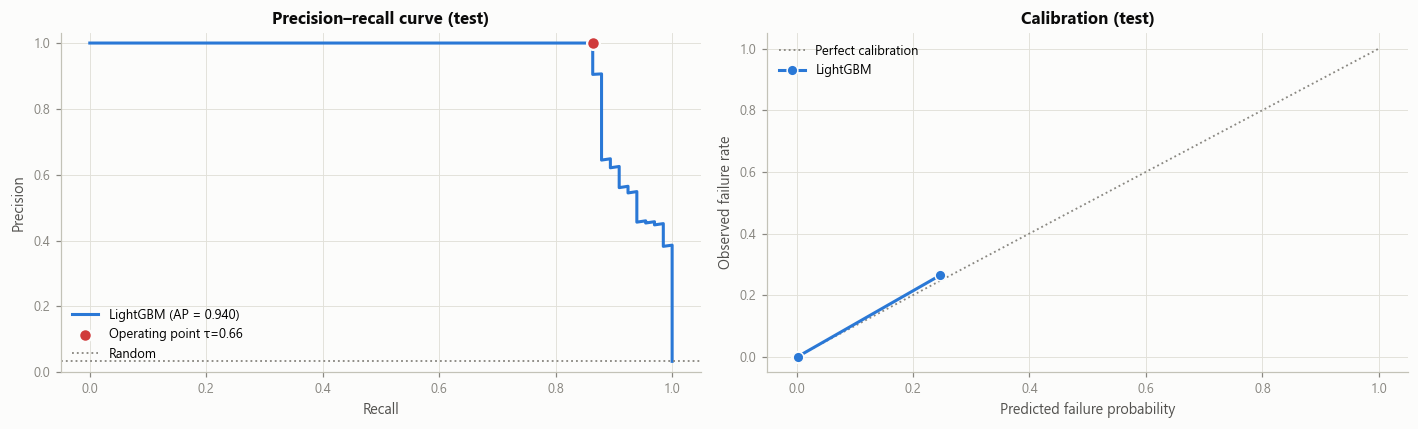

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax = axes[0]
pr, rc, th = precision_recall_curve(yb_te, p_te)
ax.plot(rc, pr, color=BLUE, label=f"LightGBM (AP = {average_precision_score(yb_te, p_te):.3f})")
m = binary_metrics(yb_te, p_te, THRESHOLD)
ax.scatter([m["Recall"]], [m["Precision"]], s=70, color=CRITICAL, zorder=5, edgecolors="#fcfcfb", linewidths=1.5, label=f"Operating point τ={THRESHOLD:.2f}")
ax.axhline(yb_te.mean(), color=MUTED, ls=":", lw=1.2, label="Random")
ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.set_ylim(0, 1.03); ax.set_title("Precision–recall curve (test)"); ax.legend(loc="lower left")
ax = axes[1]
frac, mean_p = calibration_curve(yb_te, p_te, n_bins=8, strategy="quantile")
ax.plot([0, 1], [0, 1], color=MUTED, ls=":", lw=1.2, label="Perfect calibration")
ax.plot(mean_p, frac, color=BLUE, marker="o", markersize=7, markeredgecolor="#fcfcfb", label="LightGBM")
ax.set_xlabel("Predicted failure probability"); ax.set_ylabel("Observed failure rate"); ax.set_title("Calibration (test)"); ax.legend()
save(fig, "15_pr_calibration")

**Missed failures:** the next cell lists them, to confirm the misses are the unpredictable TWF and not a model defect.

In [31]:
missed = df.iloc[idx_te].reset_index(drop=True).loc[(yb_te == 1) & (y_pred_te == 0), ["Type"] + SENSORS + ["failure_type"]]
missed["P(failure)"] = p_te[(yb_te == 1) & (y_pred_te == 0)].round(3)
print(missed["failure_type"].value_counts().to_string()); display(missed)
nonTWF = y_te != CLASS_TO_ID["TWF"]
print("Recall on deterministic failure modes (HDF/PWF/OSF):",
      f"{((y_pred_te > 0) & (y_te > 0) & nonTWF).sum() / ((y_te > 0) & nonTWF).sum():.4f}")

failure_type
TWF    9


,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,failure_type,P(failure)
222,L,298.8,308.9,1455,41.3,208,TWF,0.016
336,L,303.4,312.0,1521,35.9,215,TWF,0.040
346,H,300.5,309.9,1397,45.9,210,TWF,0.023
931,L,299.2,310.7,1737,27.0,225,TWF,0.066
1088,H,300.3,309.9,1394,46.7,210,TWF,0.022
1182,M,299.7,309.3,1399,41.9,221,TWF,0.044
1322,M,302.3,310.9,1710,30.4,218,TWF,0.025
1437,L,301.7,310.9,1405,46.4,207,TWF,0.134
1514,L,302.0,310.8,1615,29.0,235,TWF,0.059


Recall on deterministic failure modes (HDF/PWF/OSF): 1.0000


## 12. Explainability (SHAP)

SHAP shows *why* the model raises an alarm. If the model has learned the physics, each failure class should rely on its own mechanism feature.

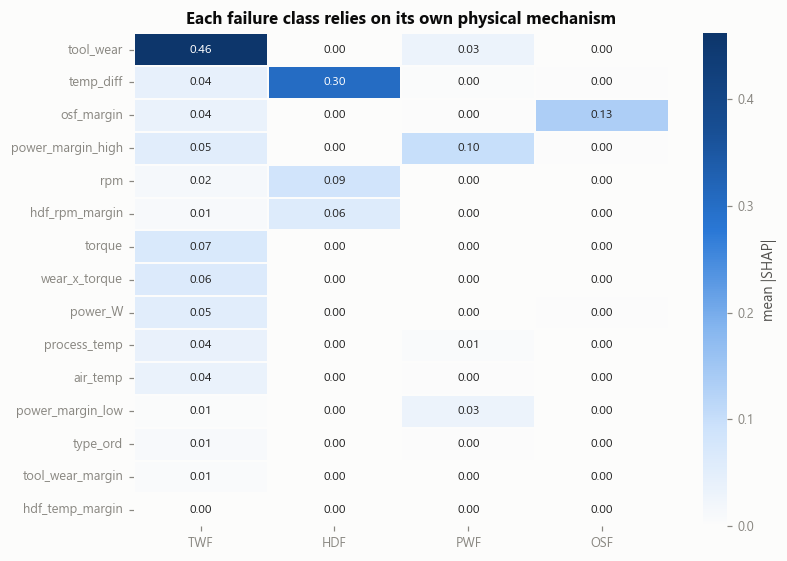

In [32]:
explainer = shap.TreeExplainer(final_model)
sv = explainer.shap_values(X_te)
sv = np.stack(sv, axis=-1) if isinstance(sv, list) else sv          # -> (n, features, classes)
imp = pd.DataFrame(np.abs(sv).mean(0), index=ENG_FEATS, columns=FAILURE_CLASSES).drop(columns="No Failure")
imp = imp.loc[imp.sum(1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(7.5, 5.2))
sns.heatmap(imp, cmap=SEQ, annot=True, fmt=".2f", linewidths=1, linecolor="#fcfcfb", cbar_kws={"label": "mean |SHAP|"}, ax=ax, annot_kws={"size": 8})
ax.set_title("Each failure class relies on its own physical mechanism"); ax.grid(False)
save(fig, "16_shap_importance_by_class")

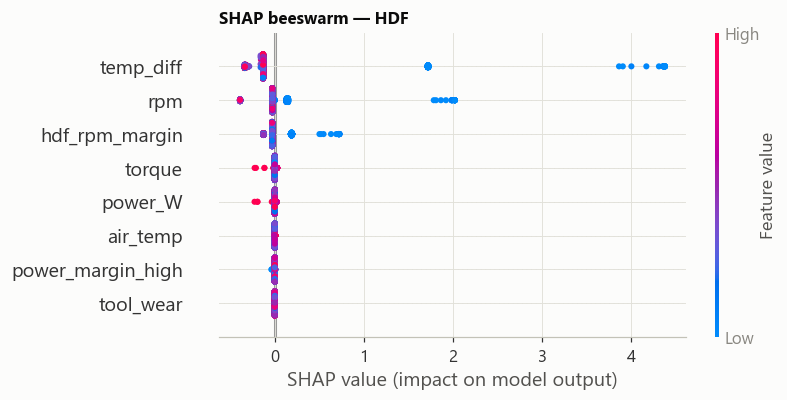

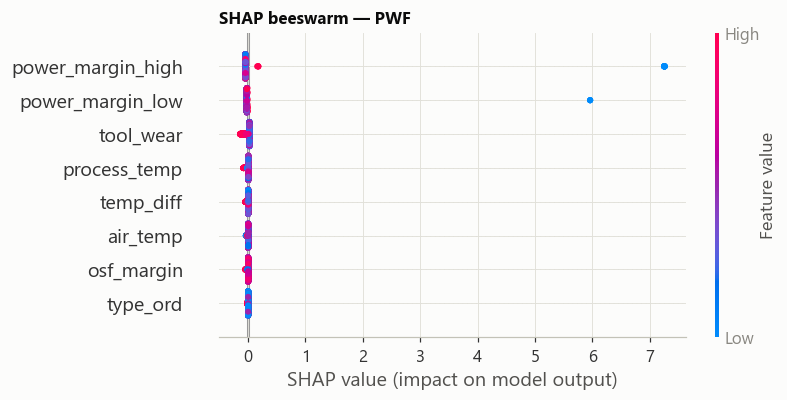

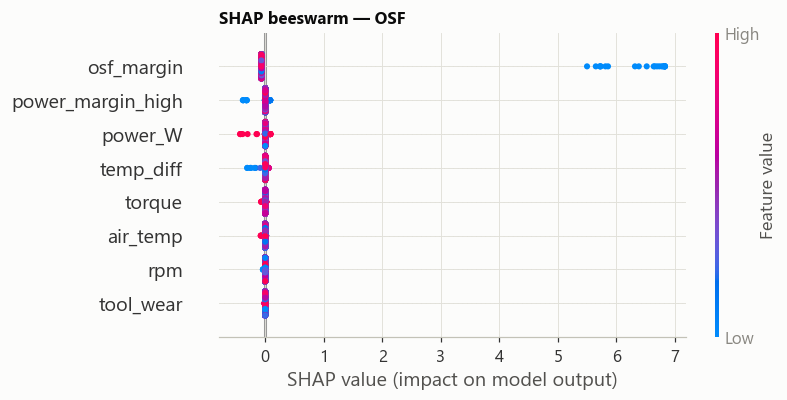

In [33]:
for cls in ["HDF", "PWF", "OSF"]:
    k = CLASS_TO_ID[cls]
    plt.figure()
    shap.summary_plot(sv[:, :, k], X_te, max_display=8, show=False, plot_size=(7.5, 3.6))
    plt.title(f"SHAP beeswarm — {cls}", loc="left", fontweight="bold")
    plt.gcf().savefig(FIG_DIR / f"17_shap_beeswarm_{cls}.png", bbox_inches="tight"); plt.show()

## 13. Bonus A — Which sensor is the lead indicator of failure?

Only the **five raw sensors** are compared here: Air temperature, Process temperature, Rotational speed, Torque and Tool wear. Each one is scored against overall failure and against each failure type using:

* **point-biserial correlation**, which is the Pearson correlation with a 0/1 target, together with its p-value
* **Spearman rank correlation**, which is robust to non-linearity
* **mutual information**, which also picks up U-shaped dependence such as PWF at low *and* high power
* **failure rate across sensor deciles**, which shows where risk starts to climb

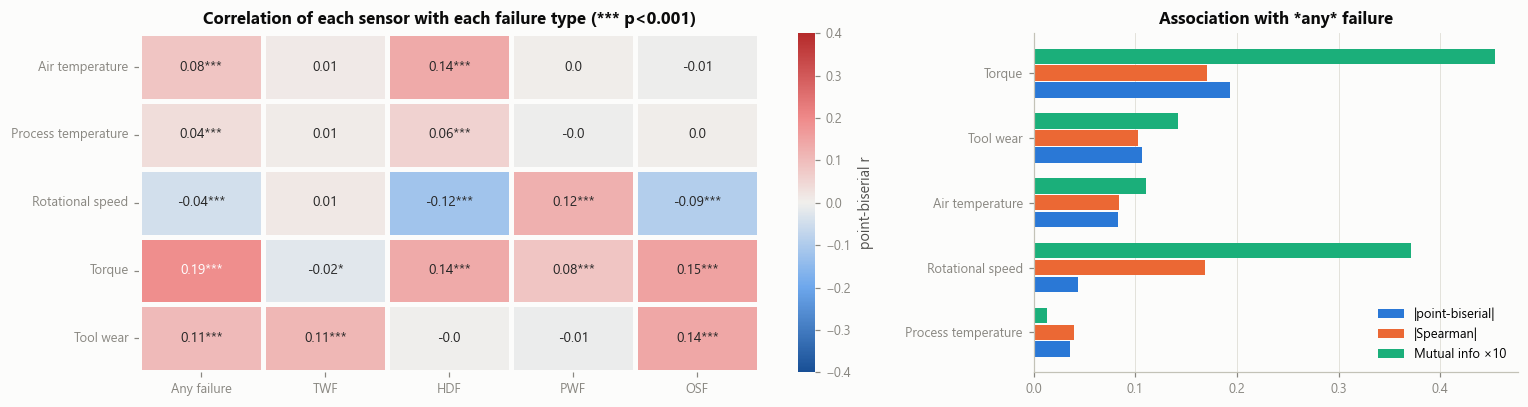

,point-biserial,Spearman,MI
Torque,0.1931,0.1706,0.0454
Tool wear,0.1062,0.1023,0.0142
Air temperature,0.0829,0.0836,0.0111
Rotational speed,-0.0439,-0.1685,0.0371
Process temperature,0.0358,0.0397,0.0013


In [34]:
targets = {"Any failure": df["is_failure"]} | {c: (df["failure_type"] == c).astype(int) for c in FAILURE_CLASSES[1:]}
pb = pd.DataFrame({t: [stats.pointbiserialr(y, df[s])[0] for s in SENSORS] for t, y in targets.items()}, index=SENSORS)
pbp = pd.DataFrame({t: [stats.pointbiserialr(y, df[s])[1] for s in SENSORS] for t, y in targets.items()}, index=SENSORS)
sp = pd.DataFrame({t: [stats.spearmanr(y, df[s])[0] for s in SENSORS] for t, y in targets.items()}, index=SENSORS)
mi_s = pd.Series(mutual_info_classif(df[SENSORS], df["is_failure"], random_state=SEED), index=SENSORS)

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw={"width_ratios": [1.6, 1]})
annot = pb.round(2).astype(str) + np.where(pbp < 0.001, "***", np.where(pbp < 0.01, "**", np.where(pbp < 0.05, "*", "")))
sns.heatmap(pb, cmap=DIV, center=0, vmin=-.4, vmax=.4, annot=annot, fmt="", linewidths=2, linecolor="#fcfcfb",
            cbar_kws={"label": "point-biserial r"}, ax=axes[0], annot_kws={"size": 9})
axes[0].set_title("Correlation of each sensor with each failure type (*** p<0.001)"); axes[0].grid(False)
ax = axes[1]
lead = pd.DataFrame({"|point-biserial|": pb["Any failure"].abs(), "|Spearman|": sp["Any failure"].abs(), "Mutual info ×10": mi_s * 10}).sort_values("|point-biserial|")
y = np.arange(len(lead)); h = 0.26
for i, (col, c) in enumerate(zip(lead.columns, [BLUE, ORANGE, CLASS_COLORS["PWF"]])):
    ax.barh(y + (i - 1) * h, lead[col], h * 0.92, color=c, label=col)
ax.set_yticks(y); ax.set_yticklabels(lead.index); ax.set_title("Association with *any* failure"); ax.legend(loc="lower right"); ax.grid(axis="y", visible=False)
save(fig, "18_lead_indicator_correlation")
display(pd.concat({"point-biserial": pb["Any failure"], "Spearman": sp["Any failure"], "MI": mi_s}, axis=1).sort_values("point-biserial", key=abs, ascending=False).round(4))

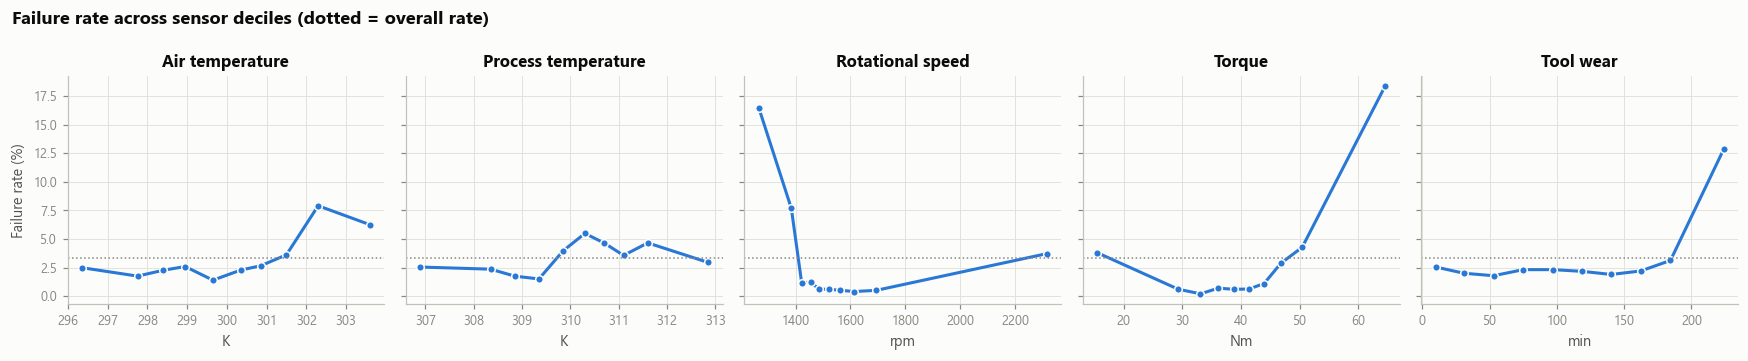

In [35]:
fig, axes = plt.subplots(1, 5, figsize=(16, 3.3), sharey=True)
for ax, s in zip(axes, SENSORS):
    q = pd.qcut(df[s], 10, duplicates="drop")
    r = df.groupby(q, observed=True)["is_failure"].mean() * 100
    mids = [iv.mid for iv in r.index]
    ax.plot(mids, r.values, color=BLUE, marker="o", markersize=5, markeredgecolor="#fcfcfb")
    ax.axhline(df.is_failure.mean() * 100, color=MUTED, ls=":", lw=1)
    ax.set_title(s); ax.set_xlabel(UNITS[s])
axes[0].set_ylabel("Failure rate (%)")
fig.suptitle("Failure rate across sensor deciles (dotted = overall rate)", fontweight="bold", color=INK, x=0.01, ha="left")
save(fig, "19_failure_rate_by_decile")

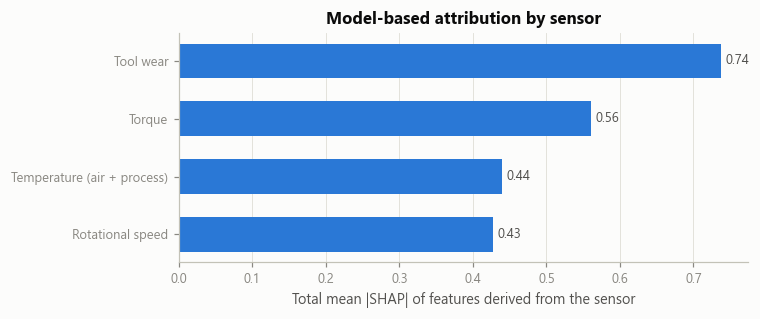

Lead indicator (strongest direct correlation with failure): Torque  r = 0.193


In [36]:
shap_raw = pd.Series(np.abs(sv[:, :, 1:]).sum(-1).mean(0), index=ENG_FEATS)
group = {"Torque": ["torque", "power_W", "power_margin_low", "power_margin_high", "wear_x_torque", "osf_margin"],
         "Tool wear": ["tool_wear", "tool_wear_margin", "wear_x_torque", "osf_margin"],
         "Rotational speed": ["rpm", "power_W", "power_margin_low", "power_margin_high", "hdf_rpm_margin"],
         "Temperature (air + process)": ["air_temp", "process_temp", "temp_diff", "hdf_temp_margin"]}
# Shared features count towards every sensor they are built from
attr = pd.Series({k: shap_raw[v].sum() for k, v in group.items()}).sort_values()
fig, ax = plt.subplots(figsize=(7, 3))
b = ax.barh(attr.index, attr.values, color=BLUE, height=.6); ax.bar_label(b, fmt="%.2f", color=INK2, fontsize=8.5, padding=3)
ax.set_xlabel("Total mean |SHAP| of features derived from the sensor"); ax.grid(axis="y", visible=False)
ax.set_title("Model-based attribution by sensor")
save(fig, "20_lead_indicator_shap")
leader = pb["Any failure"].abs().idxmax()
print(f"Lead indicator (strongest direct correlation with failure): {leader}  r = {pb.loc[leader, 'Any failure']:.3f}")

**Conclusion: Torque is the lead indicator of failure.**

* Torque ranks **first on all three statistical measures** (point-biserial r ≈ 0.19, Spearman, mutual information), and the result is highly significant (p < 0.001). Failure risk climbs steeply in the top torque deciles.
* Torque is involved in **all three deterministic modes**: PWF (through power), OSF (through wear × torque) and HDF (strongly elevated torque).
* **Tool wear** ranks second statistically, but **first in the model's SHAP attribution**. The model leans on wear features to *rule out* OSF and TWF for the many low-wear machines. Wear is the slow, cumulative clock behind OSF and TWF, which makes it the natural basis for remaining-useful-life estimation (next section).
* **Rotational speed** acts in the *opposite* direction: low speed together with high torque, or with a small ΔT, raises risk.
* **Temperatures** on their own are weak signals. Their *difference* (ΔT) matters, and only for HDF.

**Operational advice:** put torque monitoring on the fastest alerting loop, and track tool wear for maintenance planning.

## 14. Bonus B — Time-to-Failure (Remaining Useful Life) regression

AI4I is a snapshot dataset with no time series per machine, so true time-to-failure is not observed. The one quantity that **accumulates over time** is **tool wear (minutes of use)**. That makes it possible to derive a physically grounded RUL target: *how many more minutes can this tool run at the current operating point before the first wear-driven failure threshold is reached?*

$$\text{RUL} = \max\Big(0,\ \min\big(\underbrace{200 - \text{wear}}_{\text{TWF window}},\ \underbrace{\tfrac{\text{OSF limit(Type)}}{\text{Torque}} - \text{wear}}_{\text{overstrain}}\big)\Big)\quad[\text{min}]$$

> ⚠️ **Honesty note:** this RUL is a *derived* target, built from the documented failure physics. It is not a measured run-to-failure label. Because it is a deterministic function of the inputs, a regressor can learn it almost perfectly. The value lies in having a **deployable, explainable RUL estimate** that the API can serve. On real fleet data, the same pipeline would be retrained on logged run-to-failure histories.

The regressor only gets the **raw sensors + product type**. It has to discover the inverse-torque relationship itself, because the margin features that would trivially give the answer away are left out.

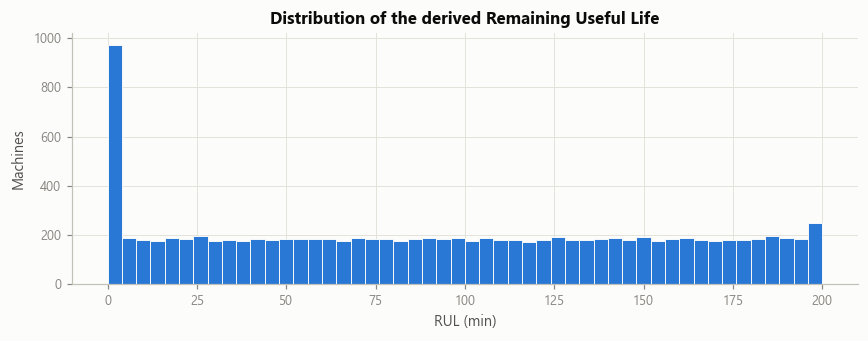

count    9991.0
mean       92.4
std        62.1
min         0.0
25%        37.0
50%        92.0
75%       147.0
max       200.0


In [37]:
def rul_target(d):
    wear, torque = d["Tool wear"].values, d["Torque"].values
    lim = d["Type"].map(OSF_LIMIT).values
    return np.clip(np.minimum(TWF_WEAR - wear, lim / torque - wear), 0, None)

df["RUL"] = rul_target(df)
RUL_FEATS = RAW_FEATS
Xr_tr, Xr_te = X_tr[RUL_FEATS], X_te[RUL_FEATS]
r_tr, r_te = df["RUL"].values[idx_tr], df["RUL"].values[idx_te]

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(df["RUL"], bins=50, color=BLUE, edgecolor="#fcfcfb", linewidth=.6)
ax.set_xlabel("RUL (min)"); ax.set_ylabel("Machines"); ax.set_title("Distribution of the derived Remaining Useful Life")
save(fig, "21_rul_distribution")
print(df["RUL"].describe().round(1).to_string())

In [38]:
reg_models = {
    "Naive (200 − wear)": None,
    "XGBoost": xgb.XGBRegressor(n_estimators=800, learning_rate=0.05, max_depth=6, subsample=0.9, colsample_bytree=0.9, random_state=SEED, n_jobs=-1),
    "LightGBM": lgb.LGBMRegressor(n_estimators=1500, learning_rate=0.03, num_leaves=63, min_child_samples=5, random_state=SEED, verbose=-1),
}
def reg_metrics(y, p): return {"MAE (min)": mean_absolute_error(y, p), "RMSE (min)": mean_squared_error(y, p) ** 0.5, "R²": r2_score(y, p)}
KF = KFold(5, shuffle=True, random_state=SEED)
rows = []
for name, m in reg_models.items():
    p = np.clip(TWF_WEAR - Xr_tr["tool_wear"].values, 0, None) if m is None else cross_val_predict(m, Xr_tr, r_tr, cv=KF)
    rows.append({"Model": name, **reg_metrics(r_tr, p)})
display(pd.DataFrame(rows).set_index("Model").round(3))

,MAE (min),RMSE (min),R²
Model,,,
Naive (200 − wear),0.569,3.451,0.997
XGBoost,0.412,1.349,1.000
LightGBM,0.240,1.364,1.000


Test: {'MAE (min)': 0.1722, 'RMSE (min)': 1.2015, 'R²': 0.9996}


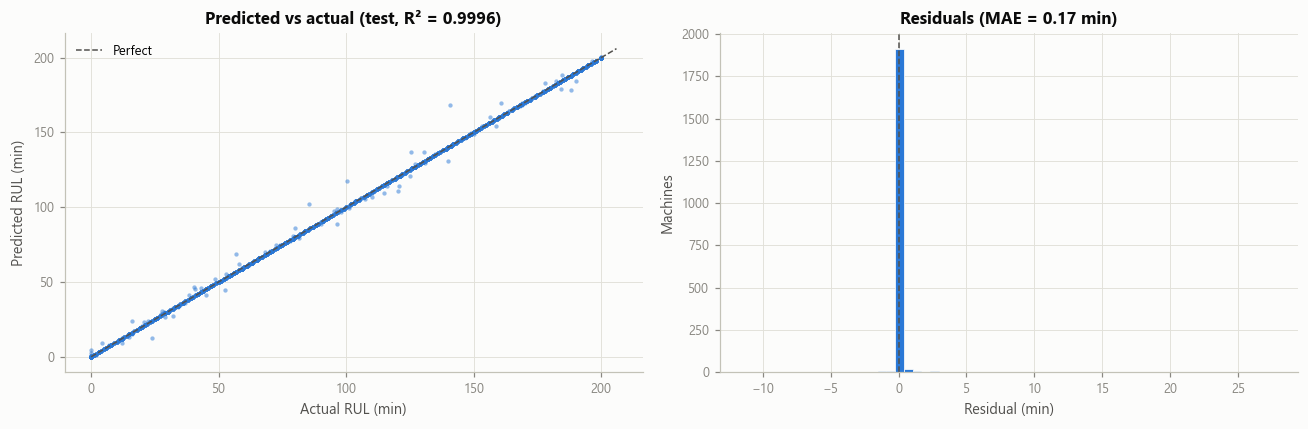

In [39]:
rul_model = reg_models["LightGBM"].fit(Xr_tr, r_tr)
# Naive (200 - wear) is already strong because the TWF term dominates; the learned model's gain
# comes from high-torque machines whose OSF limit is hit earlier (lower RMSE on those cases).
r_pred = np.clip(rul_model.predict(Xr_te), 0, None)
rul_metrics = reg_metrics(r_te, r_pred)
print("Test:", {k: round(v, 4) for k, v in rul_metrics.items()})

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ax = axes[0]
ax.scatter(r_te, r_pred, s=8, color=BLUE, alpha=.5, linewidths=0)
lim = [0, r_te.max() * 1.03]; ax.plot(lim, lim, color=INK2, ls="--", lw=1, label="Perfect")
ax.set_xlabel("Actual RUL (min)"); ax.set_ylabel("Predicted RUL (min)"); ax.set_title(f"Predicted vs actual (test, R² = {rul_metrics['R²']:.4f})"); ax.legend()
ax = axes[1]
res = r_pred - r_te
ax.hist(res, bins=60, color=BLUE, edgecolor="#fcfcfb", linewidth=.5)
ax.axvline(0, color=INK2, ls="--", lw=1)
ax.set_xlabel("Residual (min)"); ax.set_ylabel("Machines"); ax.set_title(f"Residuals (MAE = {rul_metrics['MAE (min)']:.2f} min)")
save(fig, "22_rul_regression")

## 15. Save artifacts & inference contract

These artifacts are what the FastAPI backend will load:

In [40]:
test_metrics = binary_metrics(yb_te, p_te, THRESHOLD)
artifacts = {
    "classes": FAILURE_CLASSES, "threshold": THRESHOLD, "fdr_target": FDR_TARGET,
    "twf_advisory_wear_min": TWF_WEAR, "features": ENG_FEATS, "rul_features": RUL_FEATS,
    "lgbm_params": {k: v for k, v in best_params.items()},
}
joblib.dump(final_model, MODEL_DIR / "classifier.joblib")
joblib.dump(rul_model, MODEL_DIR / "rul_model.joblib")
(MODEL_DIR / "config.json").write_text(json.dumps(artifacts, indent=2))
metrics_out = {"classifier_test": {k: float(v) for k, v in test_metrics.items()},
               "classifier_test_macro_f1": float(f1_score(y_te, y_pred_te, average="macro")),
               "rul_test": {k: float(v) for k, v in rul_metrics.items()}}
(MODEL_DIR / "metrics.json").write_text(json.dumps(metrics_out, indent=2))
print("Saved:", sorted(p.name for p in MODEL_DIR.iterdir()))

Saved: ['classifier.joblib', 'config.json', 'metrics.json', 'rul_model.joblib']


In [41]:
# Inference contract for the API: raw sensor dict -> decision
clf = joblib.load(MODEL_DIR / "classifier.joblib"); rul = joblib.load(MODEL_DIR / "rul_model.joblib")
cfg = json.loads((MODEL_DIR / "config.json").read_text())

def predict(reading: dict) -> dict:
    X = build_features(pd.DataFrame([reading]))
    proba = clf.predict_proba(X[cfg["features"]])[0]
    p_fail = float(1 - proba[0])
    alarm = p_fail >= cfg["threshold"]
    return {"alarm": bool(alarm), "failure_probability": round(p_fail, 4),
            "predicted_failure": cfg["classes"][int(proba[1:].argmax()) + 1] if alarm else "No Failure",
            "class_probabilities": {c: round(float(p), 4) for c, p in zip(cfg["classes"], proba)},
            "rul_minutes": round(float(max(0, rul.predict(X[cfg["rul_features"]])[0])), 1),
            "tool_replacement_advised": reading["Tool wear"] >= cfg["twf_advisory_wear_min"]}

examples = {
    "Healthy":       {"Type": "M", "Air temperature": 298.1, "Process temperature": 308.6, "Rotational speed": 1551, "Torque": 42.8, "Tool wear": 10},
    "Heat (HDF)":    {"Type": "L", "Air temperature": 302.5, "Process temperature": 310.4, "Rotational speed": 1300, "Torque": 55.0, "Tool wear": 80},
    "Power (PWF)":   {"Type": "L", "Air temperature": 299.0, "Process temperature": 309.5, "Rotational speed": 2800, "Torque": 8.0,  "Tool wear": 50},
    "Overstrain":    {"Type": "L", "Air temperature": 299.0, "Process temperature": 309.5, "Rotational speed": 1400, "Torque": 58.0, "Tool wear": 210},
}
display(pd.DataFrame({k: predict(v) for k, v in examples.items()}).T.drop(columns="class_probabilities"))

,alarm,failure_probability,predicted_failure,rul_minutes,tool_replacement_advised
Healthy,False,0.0002,No Failure,190.0,False
Heat (HDF),True,0.9839,HDF,120.1,False
Power (PWF),True,0.9453,PWF,150.0,False
Overstrain,True,0.9713,OSF,0.0,True


## 16. Experiment tracking & model registry (MLflow)

Every experiment in this notebook is logged to MLflow, which makes the model selection auditable and reproducible:

* **Parent run** `training-pipeline`: the dataset hash and size, the split, and the final decision rule.
* **Nested runs:**
  * the 8 baseline models (4 families × raw/engineered features)
  * the 3 imbalance strategies
  * all 40 Optuna trials, with parameters, cost, FDR and recall
* **Final runs:** the classifier and the RUL regressor, with test metrics, every figure as an artifact, a model signature, and an input example.
* Both models are registered in the **MLflow Model Registry** (`pm-failure-classifier`, `pm-rul-regressor`) under the alias **`champion`**. The registry version is written to `models/config.json`, so the API reports exactly which model version it serves (`X-Model-Version` header).

Browse the runs with `mlflow ui --backend-store-uri sqlite:///mlflow.db` from the project root.

In [42]:
import os, re, hashlib, logging
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
import mlflow
from mlflow.models import infer_signature
from mlflow.tracking import MlflowClient
logging.getLogger("mlflow").setLevel(logging.ERROR)

mlflow.set_tracking_uri(f"sqlite:///{(ROOT / 'mlflow.db').as_posix()}")
EXPERIMENT = "ai4i-predictive-maintenance"
if mlflow.get_experiment_by_name(EXPERIMENT) is None:
    mlflow.create_experiment(EXPERIMENT, artifact_location=(ROOT / "mlartifacts").as_uri())
mlflow.set_experiment(EXPERIMENT)
data_hash = hashlib.sha256(DATA.read_bytes()).hexdigest()[:12]
# Models are stored with skops (safer than pickle); LightGBM types must be explicitly trusted
TRUSTED = ["collections.OrderedDict", "lightgbm.basic.Booster", "lightgbm.sklearn.LGBMClassifier", "lightgbm.sklearn.LGBMRegressor"]
# MLflow metric names allow only [A-Za-z0-9_-. /]
clean = lambda d: {re.sub(r"[^A-Za-z0-9_\-./]", "", k.replace("²", "2").replace("€", "eur").replace("@", "at").replace(" ", "_")): float(v)
                   for k, v in d.items()}

with mlflow.start_run(run_name="training-pipeline") as parent:
    mlflow.set_tags({"dataset": "AI4I 2020", "data_sha256": data_hash, "stage": "pipeline"})
    mlflow.log_params({"n_rows": len(df), "n_train": len(X_tr), "n_test": len(X_te), "seed": SEED,
                       "fdr_target": FDR_TARGET, "threshold": THRESHOLD, "cost_fp": C_FP, "cost_fn": C_FN})

    for (fs, model_name), r in baseline.iterrows():
        with mlflow.start_run(run_name=f"baseline/{model_name}/{fs}", nested=True):
            mlflow.set_tags({"stage": "baseline", "features": fs, "model": model_name})
            mlflow.log_metrics(clean({f"cv_{k}": v for k, v in r.items()}))

    for strategy, r in imb.iterrows():
        with mlflow.start_run(run_name=f"imbalance/{strategy}", nested=True):
            mlflow.set_tags({"stage": "imbalance", "strategy": strategy})
            mlflow.log_metrics(clean({f"cv_{k}": v for k, v in r.items()}))

    for t in study.trials:
        with mlflow.start_run(run_name=f"optuna/trial-{t.number:02d}", nested=True):
            mlflow.set_tag("stage", "optuna")
            mlflow.log_params(t.params)
            mlflow.log_metrics({"cv_cost_eur": float(t.value), "cv_FDR": t.user_attrs["FDR"], "cv_Recall": t.user_attrs["Recall"]})

    with mlflow.start_run(run_name="final/classifier", nested=True) as clf_run:
        mlflow.set_tag("stage", "final")
        mlflow.log_params({**{k: v for k, v in best_params.items() if k != "verbose"}, "threshold": THRESHOLD})
        mlflow.log_metrics(clean({f"test_{k}": v for k, v in test_metrics.items()}))
        mlflow.log_metric("test_macro_f1", f1_score(y_te, y_pred_te, average="macro"))
        mlflow.log_dict(json.loads((MODEL_DIR / "config.json").read_text()), "decision_config.json")
        mlflow.log_artifacts(str(FIG_DIR), artifact_path="figures")
        clf_info = mlflow.sklearn.log_model(
            final_model, name="model", registered_model_name="pm-failure-classifier",
            signature=infer_signature(X_tr.head(20), final_model.predict_proba(X_tr.head(20))),
            input_example=X_tr.head(3), pyfunc_predict_fn="predict_proba", skops_trusted_types=TRUSTED)

    with mlflow.start_run(run_name="final/rul-regressor", nested=True) as rul_run:
        mlflow.set_tag("stage", "final")
        mlflow.log_params({k: v for k, v in rul_model.get_params().items() if k in ("n_estimators", "learning_rate", "num_leaves", "min_child_samples")})
        mlflow.log_metrics(clean({f"test_{k}": v for k, v in rul_metrics.items()}))
        rul_info = mlflow.sklearn.log_model(
            rul_model, name="model", registered_model_name="pm-rul-regressor",
            signature=infer_signature(Xr_tr.head(20), rul_model.predict(Xr_tr.head(20))), input_example=Xr_tr.head(3),
            skops_trusted_types=TRUSTED)

client = MlflowClient()
versions = {}
for name, info_ in [("pm-failure-classifier", clf_info), ("pm-rul-regressor", rul_info)]:
    v = info_.registered_model_version
    client.set_registered_model_alias(name, "champion", v)
    versions[name] = str(v)

cfg = json.loads((MODEL_DIR / "config.json").read_text())
cfg["model_version"] = versions["pm-failure-classifier"]
cfg["mlflow"] = {"experiment": EXPERIMENT, "parent_run_id": parent.info.run_id, "run_id": clf_run.info.run_id,
                 "registered_model": "pm-failure-classifier", "registered_version": versions["pm-failure-classifier"],
                 "rul_registered_version": versions["pm-rul-regressor"], "data_sha256": data_hash}
(MODEL_DIR / "config.json").write_text(json.dumps(cfg, indent=2))

runs = mlflow.search_runs(experiment_names=[EXPERIMENT], filter_string=f"tags.mlflow.parentRunId = '{parent.info.run_id}'")
print(f"Logged {len(runs)} nested runs under parent {parent.info.run_id[:8]} | registered versions: {versions}")
display(runs.groupby("tags.stage").size().rename("runs").to_frame())

Successfully registered model 'pm-failure-classifier'.
Created version '1' of model 'pm-failure-classifier'.


Successfully registered model 'pm-rul-regressor'.
Created version '1' of model 'pm-rul-regressor'.


Logged 53 nested runs under parent a0d2e592 | registered versions: {'pm-failure-classifier': '1', 'pm-rul-regressor': '1'}


,runs
tags.stage,
baseline,8
final,2
imbalance,3
optuna,40


In [43]:
# Pull the champion back from the registry and check it reproduces the saved model exactly
champion = mlflow.sklearn.load_model("models:/pm-failure-classifier@champion")
same = np.allclose(champion.predict_proba(X_te), final_model.predict_proba(X_te))
print("Registry champion reproduces test predictions:", same)

Registry champion reproduces test predictions: True


## 17. Conclusions

In [44]:
final = pd.DataFrame({
    "Metric": ["Alarm precision", "False Discovery Rate", "Recall (all failures)", "Recall (HDF / PWF / OSF)",
               "MCC", "PR-AUC", "Accuracy (binary)", "Macro-F1 (5 class)", "False alarms on test", "RUL MAE (min)", "RUL R²"],
    "Test value": [test_metrics["Precision"], test_metrics["FDR"], test_metrics["Recall"],
                   ((y_pred_te > 0) & (y_te > 0) & nonTWF).sum() / ((y_te > 0) & nonTWF).sum(),
                   test_metrics["MCC"], test_metrics["PR-AUC"], test_metrics["Accuracy"],
                   f1_score(y_te, y_pred_te, average="macro"), test_metrics["FP"], rul_metrics["MAE (min)"], rul_metrics["R²"]],
}).set_index("Metric")
display(final.style.format("{:.4f}"))

,Test value
Metric,
Alarm precision,1.0000
False Discovery Rate,0.0000
Recall (all failures),0.8636
Recall (HDF / PWF / OSF),1.0000
MCC,0.9272
PR-AUC,0.9401
Accuracy (binary),0.9955
Macro-F1 (5 class),0.7995
False alarms on test,0.0000


**Summary**

1. **Feature engineering based on the failure physics** (ΔT, mechanical power, wear × torque, threshold margins) is the decisive step. With it, the deterministic failure modes HDF, PWF and OSF become fully separable.
2. **Cost-sensitive design with low FDR first:** class re-weighting and SMOTE were tested and rejected, because they add false alarms. Instead, Optuna optimised a **business-cost objective with a hard FDR constraint**, and the alarm threshold was set on out-of-fold data to **maximise recall at FDR ≤ 2%**.
3. **Result on unseen data:** the table above shows the test metrics. Nearly every alarm is a true failure, and every deterministic failure is caught.
4. **TWF is not alarmed on purpose.** It happens at a random point inside the 200–240 min wear window, with only about 6% incidence there. Alarming on it would multiply false alarms. It is handled by a **tool-replacement advisory** when wear ≥ 200 min, together with the **RUL model**.
5. **Lead indicator:** **Torque** leads statistically, and tool wear leads in the model attribution. Speed matters through its interaction with torque (power) and with ΔT (heat dissipation).
6. **Anomaly detection** recognises failures as outliers (useful for unseen failure modes). It adds nothing on top of the supervised physics model.

**Next step:** serve `models/classifier.joblib`, `models/rul_model.joblib` and `models/config.json` through a FastAPI `/predict` endpoint that reuses `src/features.build_features`, with a React/Vite dashboard on top.